# Exploratory Data Analysis for IBM Employee Attrition 

# TODO : 
- continue the observations about column groups : Done

I reached where those enorumos plotting exists. 

- see the correlation matrix between attrition as 0 and 1 and the other numerical values


- add observations about those categorical columns plots and organize them in a similar way to what we did previously
also plot the most useful ones alone

- add some observations about distributions



### Problem Scope

Identify factors associated with employee attrition.

Which employee, job, compensation, and satisfaction characteristics are associated with higher attrition rates?

### Dataset Description

dataset link : https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/data

the dataset has 1470 record about employees // TODO  complete this description in the end

### Libraries & Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [3]:
df = pd.read_csv("./data.csv")

In [4]:
df.shape

(1470, 35)

In [5]:
pd.options.display.max_columns = None
pd.options.display.max_rows = 100
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [6]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,2,Male,82,4,2,Laboratory Technician,3,Married,4404,10228,2,Y,No,12,3,1,80,0,6,3,4,4,3,1,2


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

checking for missing values & duplicated records

In [8]:
df.isna().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

our data has no missing values or duplicated rows

considering first and last 5 rows from the dataset  , we can see that EmployeeCount column and Over18 columns maybe useless

In [10]:
df.nunique().sort_values() 

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

confirmed that columns "EmployeeCount","Over18" are unneceasssry in addition to "StandardHours", we can drop them

In [11]:
df['EmployeeNumber'].nunique()

1470

"EmployeeNumber" acts as ID , we can drop it also.

In [12]:
df.drop(columns=["EmployeeCount","Over18","StandardHours","EmployeeNumber"],inplace=True)

## Categorical And Numerical Columns

considering the number of unique values, these columns could be categorical columns:
```
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
JobRole                        9
Age                           43
```

although "TrainingTimeLastYear" has low unique values , it is not categorical # Maybe removing this cell is better

In [13]:
df.dtypes

Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StockOptionLevel             int64
TotalWorkingYears            int64
TrainingTimesLastYear        int64
WorkLifeBalance              int64
YearsAtCompany               int64
YearsInCurrentRole  

since we have only object and int64 datatypes , we can initially classify them: 

In [14]:
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
cat_cols.remove("Attrition") 
num_cols = df.select_dtypes(include=["int64"]).columns.tolist()

In [15]:
cat_cols

['BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'OverTime']

In [16]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

A lot of the categorical columns considering the data from kaggle and columns labels uses integers, we will convert them for readablity

lets explore columns that have small unique values number and convert them:

In [17]:
for col in num_cols:
  if df[col].nunique()< 10:
    print(f"{col} : {df[col].unique()}")

Education : [2 1 4 3 5]
EnvironmentSatisfaction : [2 3 4 1]
JobInvolvement : [3 2 4 1]
JobLevel : [2 1 3 4 5]
JobSatisfaction : [4 2 3 1]
PerformanceRating : [3 4]
RelationshipSatisfaction : [1 4 2 3]
StockOptionLevel : [0 1 3 2]
TrainingTimesLastYear : [0 3 2 5 1 4 6]
WorkLifeBalance : [1 3 2 4]


most of the columns are mentiond in kaggle website to be categorical, except JobLevel ,StockOptionLevel and TrainingTimesLastYear (These are not mentioned)

obviously TrainingTimesLastYear is not a categorical column even if it has small number of values


In [18]:
from pandas.api.types import CategoricalDtype

# Mapping dictionaries
education = {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"} 
environment_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
job_involvement = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
job_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
performance_rating = {1: "Low", 2: "Good", 3: "Excellent", 4: "Outstanding"} 
relationship_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
worklife_balance = {1: "Bad", 2: "Good", 3: "Better", 4: "Best"} 
job_map = {1: "Entry", 2: "Intermediate", 3: "Senior", 4: "Lead", 5: "Executive"} 
stock_map = {0: "None", 1: "Low", 2: "Medium", 3: "High"} 

# Ordered categories for each variable
ordered_mappings = {
    "Education": list(education.values()),
    "EnvironmentSatisfaction": list(environment_satisfaction.values()),
    "JobInvolvement": list(job_involvement.values()),
    "JobSatisfaction": list(job_satisfaction.values()),
    "PerformanceRating": list(performance_rating.values()),
    "RelationshipSatisfaction": list(relationship_satisfaction.values()),
    "WorkLifeBalance": list(worklife_balance.values()),
    "JobLevel": list(job_map.values()),
    "StockOptionLevel": list(stock_map.values())
}

# Mapping numeric codes to labels
df["Education"] = df["Education"].map(education)
df["EnvironmentSatisfaction"] = df["EnvironmentSatisfaction"].map(environment_satisfaction)
df["JobInvolvement"] = df["JobInvolvement"].map(job_involvement)
df["JobSatisfaction"] = df["JobSatisfaction"].map(job_satisfaction)
df["PerformanceRating"] = df["PerformanceRating"].map(performance_rating)
df["RelationshipSatisfaction"] = df["RelationshipSatisfaction"].map(relationship_satisfaction)
df["WorkLifeBalance"] = df["WorkLifeBalance"].map(worklife_balance)
df["JobLevel"] = df["JobLevel"].map(job_map)
df["StockOptionLevel"] = df["StockOptionLevel"].map(stock_map)

# Convert all to ordered categorical
for col, order in ordered_mappings.items():
    dtype = CategoricalDtype(categories=order, ordered=True)
    df[col] = df[col].astype(dtype)

now we can check our datatypes to make sure everything is right 

In [19]:
df.dtypes

Age                            int64
Attrition                     object
BusinessTravel                object
DailyRate                      int64
Department                    object
DistanceFromHome               int64
Education                   category
EducationField                object
EnvironmentSatisfaction     category
Gender                        object
HourlyRate                     int64
JobInvolvement              category
JobLevel                    category
JobRole                       object
JobSatisfaction             category
MaritalStatus                 object
MonthlyIncome                  int64
MonthlyRate                    int64
NumCompaniesWorked             int64
OverTime                      object
PercentSalaryHike              int64
PerformanceRating           category
RelationshipSatisfaction    category
StockOptionLevel            category
TotalWorkingYears              int64
TrainingTimesLastYear          int64
WorkLifeBalance             category
Y

In [20]:
cat_cols = df.select_dtypes(include=["object",'category']).columns.tolist()
cat_cols.remove("Attrition") 
num_cols = df.select_dtypes(include=["int64"]).columns.tolist()

In [21]:
for col in cat_cols:
  print(f"{col}: {df[col].unique()}")

BusinessTravel: ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']
Department: ['Sales' 'Research & Development' 'Human Resources']
Education: ['College', 'Below College', 'Master', 'Bachelor', 'Doctor']
Categories (5, object): ['Below College' < 'College' < 'Bachelor' < 'Master' < 'Doctor']
EducationField: ['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']
EnvironmentSatisfaction: ['Medium', 'High', 'Very High', 'Low']
Categories (4, object): ['Low' < 'Medium' < 'High' < 'Very High']
Gender: ['Female' 'Male']
JobInvolvement: ['High', 'Medium', 'Very High', 'Low']
Categories (4, object): ['Low' < 'Medium' < 'High' < 'Very High']
JobLevel: ['Intermediate', 'Entry', 'Senior', 'Lead', 'Executive']
Categories (5, object): ['Entry' < 'Intermediate' < 'Senior' < 'Lead' < 'Executive']
JobRole: ['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Direc

In [22]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'HourlyRate',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

In [23]:
cat_cols

['BusinessTravel',
 'Department',
 'Education',
 'EducationField',
 'EnvironmentSatisfaction',
 'Gender',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'OverTime',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'WorkLifeBalance']

we can split columns into categories, and make an analysis for each category alone

In [24]:
column_groups = {
    "Compensation": [
        "HourlyRate", "DailyRate", "MonthlyRate",
        "MonthlyIncome", "PercentSalaryHike", "StockOptionLevel"
    ],

    "Career History": [
        "TotalWorkingYears", "YearsAtCompany",
        "YearsInCurrentRole", "YearsSinceLastPromotion",
        "YearsWithCurrManager", "NumCompaniesWorked"
    ],

    "Education and Development": [
        "Education", "EducationField", # "TrainingTimesLastYear" we will handle this column in a seperate way.
    ],

    "Demographics and Personal Life": [
        "Age", "Gender", "MaritalStatus"
    ],

    "Job and Satisfaction": [
        "EnvironmentSatisfaction", "JobInvolvement",
        "JobLevel", "JobRole", "JobSatisfaction",
        "PerformanceRating", "WorkLifeBalance"
    ],

    "Work Conditions": [
        "OverTime", "BusinessTravel", "DistanceFromHome"
    ],

    "Organization": [
        "Department"
    ],
}

lets plot the data considering Attrition to get better understanding of it

In [25]:
from pandas.api.types import is_numeric_dtype
color_map = {"Yes": "orange", "No": "#3274A1"}

def plot_category(
    df,
    column_groups,
    category,
    target="Attrition",
    n_cols=3
):
    if category not in column_groups:
        available = ", ".join(column_groups.keys())
        raise ValueError(
            f"Unknown category '{category}'. Available categories: {available}"
        )

    columns = [
        column for column in column_groups[category]
        if column in df.columns and column != target
    ]

    if not columns:
        raise ValueError(f"No valid columns found for '{category}'.")

    n_rows = math.ceil(len(columns) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4.5 * n_rows)
    )

    axes = np.atleast_1d(axes).flatten()

    for index, column in enumerate(columns):
        ax = axes[index]

        if is_numeric_dtype(df[column]):
            # Numerical columns: compare distributions by attrition
            sns.boxplot(
                data=df,
                x=target,
                y=column,
                hue=target,
                palette=color_map,
                legend=False,
                ax=ax
            )
            ax.set_xlabel("Attrition")
            ax.set_ylabel(column)

        else:
            # Categorical columns: compare attrition counts
            sns.countplot(
                data=df,
                x=column,
                hue=target,
                palette=color_map,
                ax=ax
            )
            ax.set_xlabel(column)
            ax.set_ylabel("Employee Count")
            ax.tick_params(axis="x", rotation=45)

        ax.set_title(f"{column} vs {target}")

    # Remove unused subplot axes
    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    fig.suptitle(f"{category} Analysis", fontsize=16)
    plt.tight_layout()
    plt.show()

    return fig, axes


from IPython.display import display


def display_category_tables(
    df,
    column_groups,
    category,
    target="Attrition"
):
    columns = [
        column for column in column_groups[category]
        if column in df.columns and column != target
    ]

    for column in columns:
        table = pd.crosstab(df[column], df[target])
        table = table.reindex(columns=["No", "Yes"], fill_value=0)

        table["Total"] = table["No"] + table["Yes"]
        table["AttritionRate"] = (
            table["Yes"] / table["Total"] * 100
        ).round(2)

        table = table.reset_index()
        table.columns.name = None
        table = table.rename(columns={column: column})

        print(f"\n{column}")
        display(table)

### Compensation

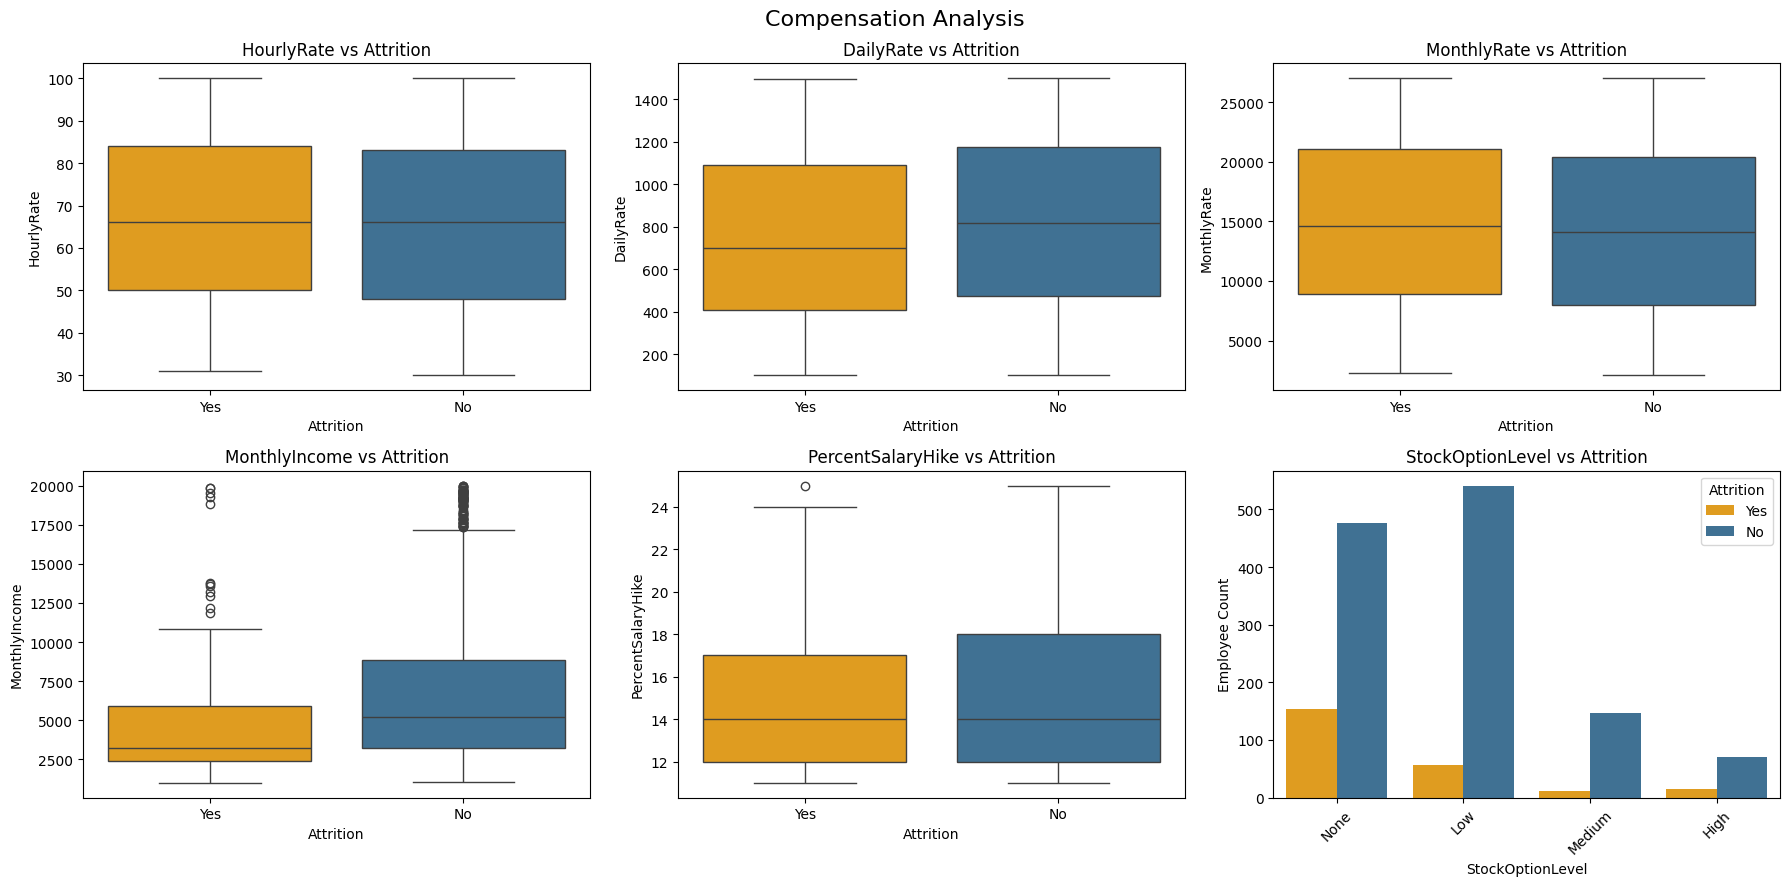

(<Figure size 1800x900 with 6 Axes>,
 array([<Axes: title={'center': 'HourlyRate vs Attrition'}, xlabel='Attrition', ylabel='HourlyRate'>,
        <Axes: title={'center': 'DailyRate vs Attrition'}, xlabel='Attrition', ylabel='DailyRate'>,
        <Axes: title={'center': 'MonthlyRate vs Attrition'}, xlabel='Attrition', ylabel='MonthlyRate'>,
        <Axes: title={'center': 'MonthlyIncome vs Attrition'}, xlabel='Attrition', ylabel='MonthlyIncome'>,
        <Axes: title={'center': 'PercentSalaryHike vs Attrition'}, xlabel='Attrition', ylabel='PercentSalaryHike'>,
        <Axes: title={'center': 'StockOptionLevel vs Attrition'}, xlabel='StockOptionLevel', ylabel='Employee Count'>],
       dtype=object))

In [26]:
plot_category(df,column_groups,"Compensation")

In [27]:
display_category_tables(df,column_groups,"Compensation")


HourlyRate


,HourlyRate,No,Yes,Total,AttritionRate
0,30,19,0,19,0.00
1,31,13,2,15,13.33
2,32,20,4,24,16.67
3,33,16,3,19,15.79
4,34,7,5,12,41.67
5,35,17,1,18,5.56
6,36,13,5,18,27.78
7,37,15,3,18,16.67
8,38,9,4,13,30.77
9,39,13,4,17,23.53



DailyRate


,DailyRate,No,Yes,Total,AttritionRate
0,102,1,0,1,0.0
1,103,0,1,1,100.0
2,104,0,1,1,100.0
3,105,1,0,1,0.0
4,106,1,0,1,0.0
...,...,...,...,...,...
881,1492,1,0,1,0.0
882,1495,3,0,3,0.0
883,1496,1,1,2,50.0
884,1498,1,0,1,0.0



MonthlyRate


,MonthlyRate,No,Yes,Total,AttritionRate
0,2094,1,0,1,0.0
1,2097,1,0,1,0.0
2,2104,1,0,1,0.0
3,2112,1,0,1,0.0
4,2122,1,0,1,0.0
...,...,...,...,...,...
1422,26956,0,1,1,100.0
1423,26959,0,1,1,100.0
1424,26968,1,0,1,0.0
1425,26997,1,0,1,0.0


... (2 outputs left out)


PercentSalaryHike


,PercentSalaryHike,No,Yes,Total,AttritionRate
0,11,169,41,210,19.52
1,12,165,33,198,16.67
2,13,175,34,209,16.27
3,14,177,24,201,11.94
4,15,83,18,101,17.82
5,16,64,14,78,17.95
6,17,68,14,82,17.07
7,18,76,13,89,14.61
8,19,67,9,76,11.84
9,20,48,7,55,12.73



StockOptionLevel


,StockOptionLevel,No,Yes,Total,AttritionRate
0,None,477,154,631,24.41
1,Low,540,56,596,9.40
2,Medium,146,12,158,7.59
3,High,70,15,85,17.65


In [28]:
stock_summary = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("StockOptionLevel", observed=True)
      .agg(
          Employees=("Left", "size"),
          EmployeesLeft=("Left", "sum"),
          AttritionRate=("Left", "mean")
      )
      .assign(AttritionRate=lambda x: x["AttritionRate"].mul(100))
      .reset_index()
)

stock_summary

,StockOptionLevel,Employees,EmployeesLeft,AttritionRate
0,None,631,154,24.405705
1,Low,596,56,9.395973
2,Medium,158,12,7.594937
3,High,85,15,17.647059


- The distributions of HourlyRate, DailyRate, MonthlyRate, and PercentSalaryHike appear similar for employees who stayed and those who left. Therefore, no strong association with attrition is apparent from these plots.

- Employees who left have a lower average MonthlyIncome than employees who stayed. This suggests that lower income may be associated with higher attrition

- Employees with no stock options had a 24.4% attrition rate, compared with 16.1% overall. Employees with low or medium stock options had lower attrition rates. The high-stock-option group had a smaller sample and its attrition rate was closer to the overall rate, so the relationship is not strictly linear.

### Career History

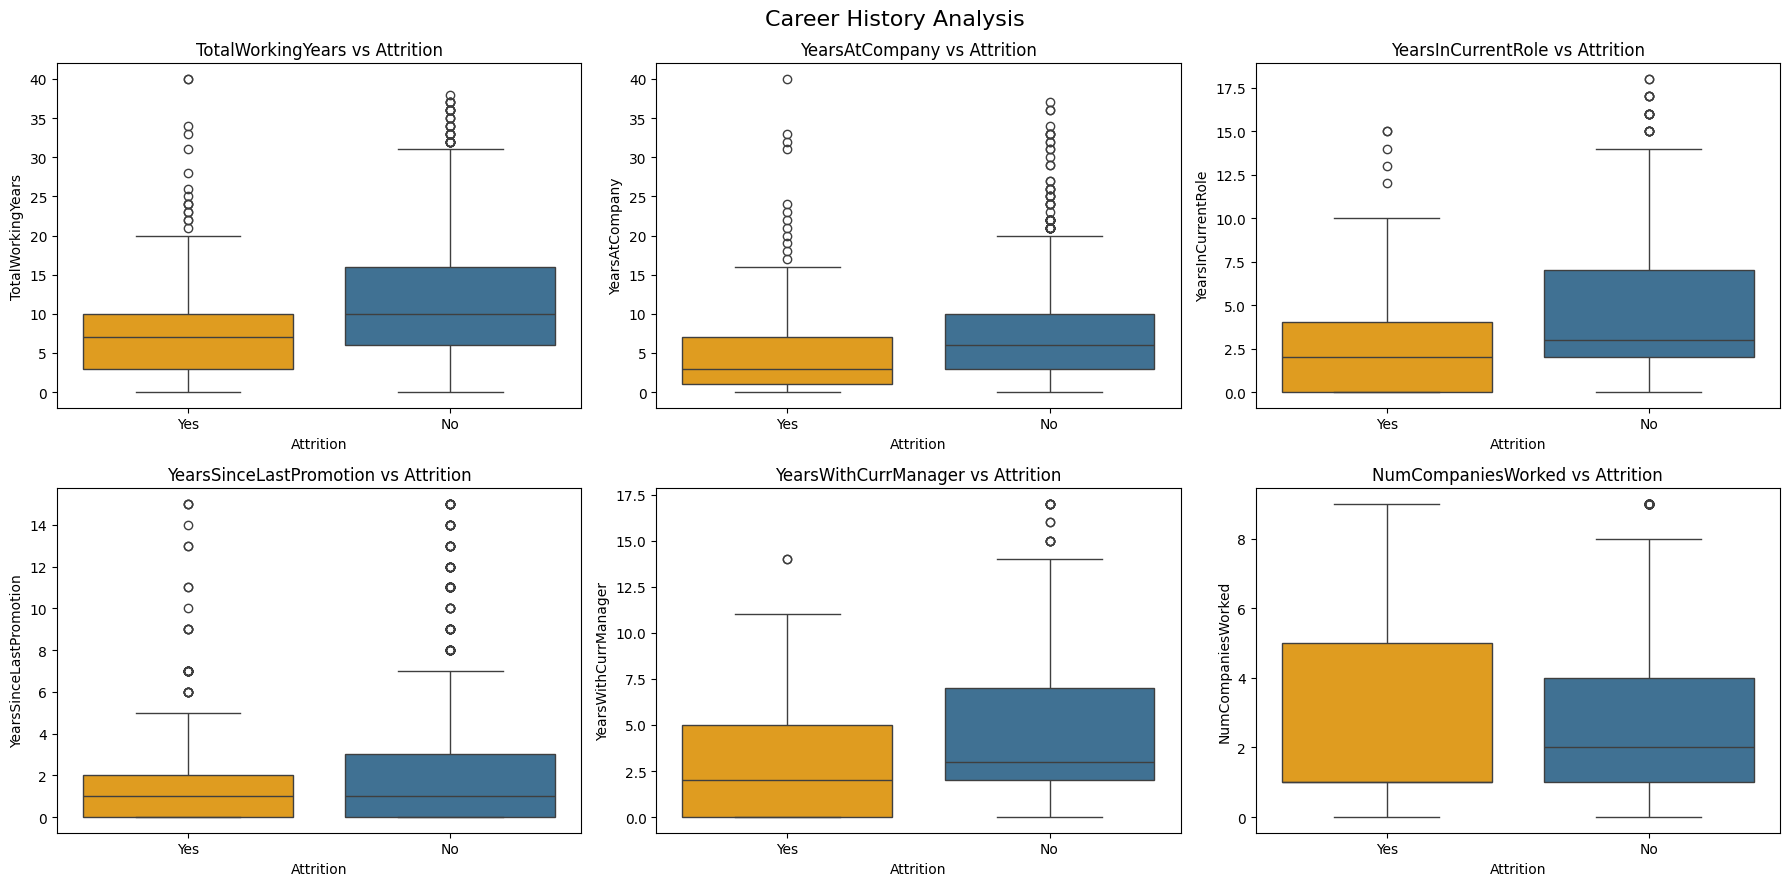

(<Figure size 1800x900 with 6 Axes>,
 array([<Axes: title={'center': 'TotalWorkingYears vs Attrition'}, xlabel='Attrition', ylabel='TotalWorkingYears'>,
        <Axes: title={'center': 'YearsAtCompany vs Attrition'}, xlabel='Attrition', ylabel='YearsAtCompany'>,
        <Axes: title={'center': 'YearsInCurrentRole vs Attrition'}, xlabel='Attrition', ylabel='YearsInCurrentRole'>,
        <Axes: title={'center': 'YearsSinceLastPromotion vs Attrition'}, xlabel='Attrition', ylabel='YearsSinceLastPromotion'>,
        <Axes: title={'center': 'YearsWithCurrManager vs Attrition'}, xlabel='Attrition', ylabel='YearsWithCurrManager'>,
        <Axes: title={'center': 'NumCompaniesWorked vs Attrition'}, xlabel='Attrition', ylabel='NumCompaniesWorked'>],
       dtype=object))

In [29]:
plot_category(df,column_groups,"Career History")

In [30]:
display_category_tables(df,column_groups,"Career History")


TotalWorkingYears


,TotalWorkingYears,No,Yes,Total,AttritionRate
0,0,6,5,11,45.45
1,1,41,40,81,49.38
2,2,22,9,31,29.03
3,3,33,9,42,21.43
4,4,51,12,63,19.05
5,5,72,16,88,18.18
6,6,103,22,125,17.60
7,7,63,18,81,22.22
8,8,87,16,103,15.53
9,9,86,10,96,10.42



YearsAtCompany


,YearsAtCompany,No,Yes,Total,AttritionRate
0,0,28,16,44,36.36
1,1,112,59,171,34.50
2,2,100,27,127,21.26
3,3,108,20,128,15.62
4,4,91,19,110,17.27
5,5,175,21,196,10.71
6,6,67,9,76,11.84
7,7,79,11,90,12.22
8,8,71,9,80,11.25
9,9,74,8,82,9.76



YearsInCurrentRole


,YearsInCurrentRole,No,Yes,Total,AttritionRate
0,0,171,73,244,29.92
1,1,46,11,57,19.30
2,2,304,68,372,18.28
3,3,119,16,135,11.85
4,4,89,15,104,14.42
5,5,35,1,36,2.78
6,6,35,2,37,5.41
7,7,191,31,222,13.96
8,8,82,7,89,7.87
9,9,61,6,67,8.96


... (2 outputs left out)


YearsWithCurrManager


,YearsWithCurrManager,No,Yes,Total,AttritionRate
0,0,178,85,263,32.32
1,1,65,11,76,14.47
2,2,294,50,344,14.53
3,3,123,19,142,13.38
4,4,87,11,98,11.22
5,5,27,4,31,12.90
6,6,25,4,29,13.79
7,7,185,31,216,14.35
8,8,97,10,107,9.35
9,9,58,6,64,9.38



NumCompaniesWorked


,NumCompaniesWorked,No,Yes,Total,AttritionRate
0,0,174,23,197,11.68
1,1,423,98,521,18.81
2,2,130,16,146,10.96
3,3,143,16,159,10.06
4,4,122,17,139,12.23
5,5,47,16,63,25.40
6,6,54,16,70,22.86
7,7,57,17,74,22.97
8,8,43,6,49,12.24
9,9,40,12,52,23.08


Employees with fewer years at the company generally show higher attrition rates. However, this is an observed association, not proof that shorter tenure causes employees to leave. The number of employees in each group should also be considered.

### Education and Development

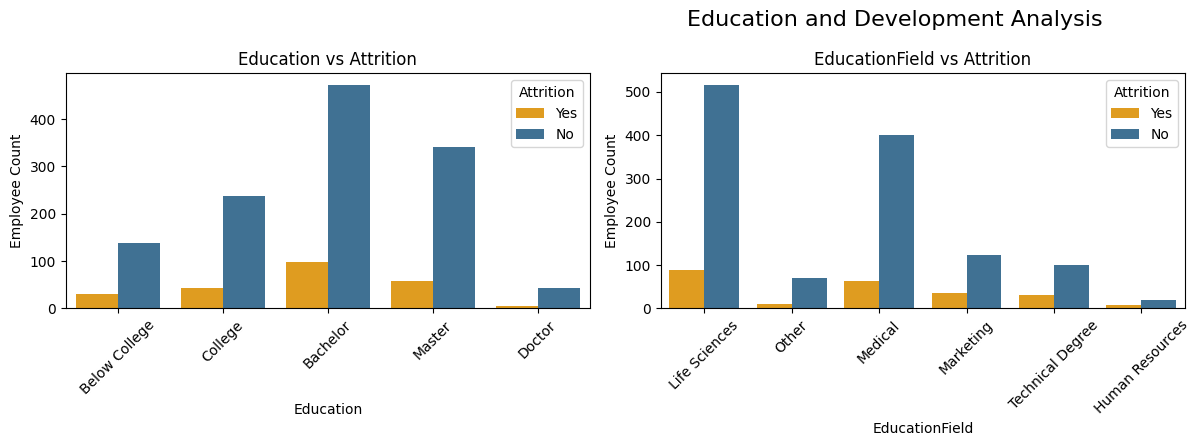

(<Figure size 1800x450 with 2 Axes>,
 array([<Axes: title={'center': 'Education vs Attrition'}, xlabel='Education', ylabel='Employee Count'>,
        <Axes: title={'center': 'EducationField vs Attrition'}, xlabel='EducationField', ylabel='Employee Count'>,
        <Axes: >], dtype=object))

In [31]:
plot_category(df,column_groups,"Education and Development")

In [32]:
display_category_tables(df,column_groups,"Education and Development")


Education


,Education,No,Yes,Total,AttritionRate
0,Below College,139,31,170,18.24
1,College,238,44,282,15.60
2,Bachelor,473,99,572,17.31
3,Master,340,58,398,14.57
4,Doctor,43,5,48,10.42



EducationField


,EducationField,No,Yes,Total,AttritionRate
0,Human Resources,20,7,27,25.93
1,Life Sciences,517,89,606,14.69
2,Marketing,124,35,159,22.01
3,Medical,401,63,464,13.58
4,Other,71,11,82,13.41
5,Technical Degree,100,32,132,24.24


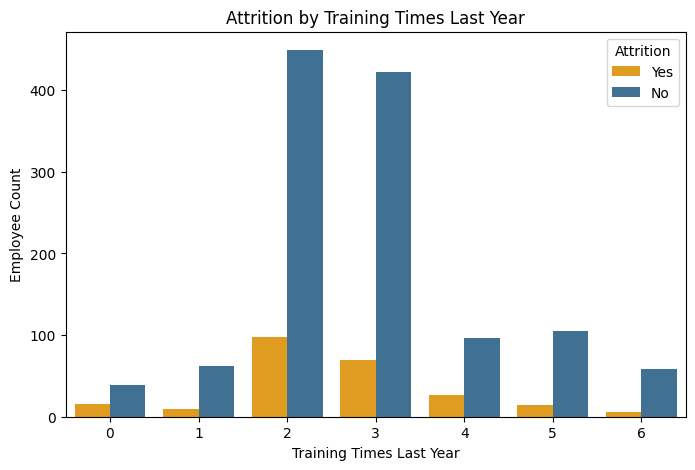

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TrainingTimesLastYear",
    hue="Attrition",
    palette=color_map
)

plt.xlabel("Training Times Last Year")
plt.ylabel("Employee Count")
plt.title("Attrition by Training Times Last Year")
plt.show()

In [34]:
training_summary = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("TrainingTimesLastYear")["Left"]
      .agg(
          Employees="size",
          EmployeesLeft="sum",
          AttritionRate="mean"
      )
      .assign(
          AttritionRate=lambda table: table["AttritionRate"].mul(100)
      )
      .reset_index()
)

training_summary

,TrainingTimesLastYear,Employees,EmployeesLeft,AttritionRate
0,0,54,15,27.777778
1,1,71,9,12.676056
2,2,547,98,17.915905
3,3,491,69,14.052953
4,4,123,26,21.138211
5,5,119,14,11.764706
6,6,65,6,9.230769


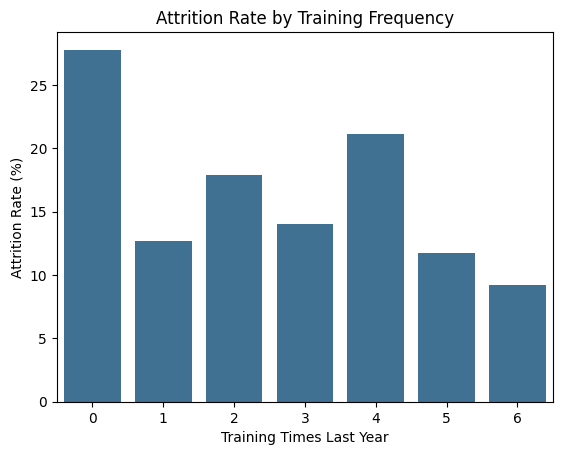

In [35]:
sns.barplot(
    data=training_summary,
    x="TrainingTimesLastYear",
    y="AttritionRate",
    color="#3274A1"
)

plt.ylabel("Attrition Rate (%)")
plt.xlabel("Training Times Last Year")
plt.title("Attrition Rate by Training Frequency")
plt.show()

In [36]:
for column in [
    "Education",
    "EducationField",
    "TrainingTimesLastYear"
]:
    print(f"\n{column}")

    table = pd.crosstab(
        df[column],
        df["Attrition"],
        normalize="index"
    ).mul(100).round(2)

    print(table)


Education
Attrition         No    Yes
Education                  
Below College  81.76  18.24
College        84.40  15.60
Bachelor       82.69  17.31
Master         85.43  14.57
Doctor         89.58  10.42

EducationField
Attrition            No    Yes
EducationField                
Human Resources   74.07  25.93
Life Sciences     85.31  14.69
Marketing         77.99  22.01
Medical           86.42  13.58
Other             86.59  13.41
Technical Degree  75.76  24.24

TrainingTimesLastYear
Attrition                 No    Yes
TrainingTimesLastYear              
0                      72.22  27.78
1                      87.32  12.68
2                      82.08  17.92
3                      85.95  14.05
4                      78.86  21.14
5                      88.24  11.76
6                      90.77   9.23


Attrition rates are relatively similar across education levels, Education Fields and Training times last year, so this dataset does not show a strong association between an employee’s education and attrition.

### Demographics and Personal Life

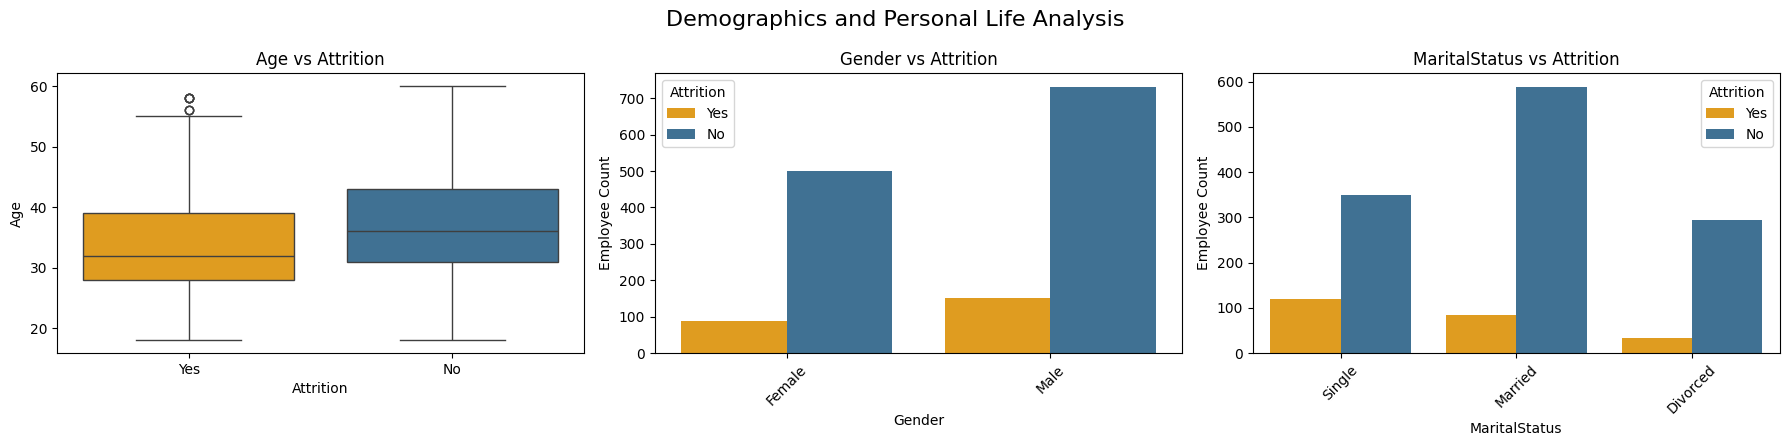

(<Figure size 1800x450 with 3 Axes>,
 array([<Axes: title={'center': 'Age vs Attrition'}, xlabel='Attrition', ylabel='Age'>,
        <Axes: title={'center': 'Gender vs Attrition'}, xlabel='Gender', ylabel='Employee Count'>,
        <Axes: title={'center': 'MaritalStatus vs Attrition'}, xlabel='MaritalStatus', ylabel='Employee Count'>],
       dtype=object))

In [37]:
plot_category(df,column_groups,"Demographics and Personal Life")


In [38]:
display_category_tables(df,column_groups,"Demographics and Personal Life")



Age


,Age,No,Yes,Total,AttritionRate
0,18,4,4,8,50.00
1,19,3,6,9,66.67
2,20,5,6,11,54.55
3,21,7,6,13,46.15
4,22,11,5,16,31.25
5,23,10,4,14,28.57
6,24,19,7,26,26.92
7,25,20,6,26,23.08
8,26,27,12,39,30.77
9,27,45,3,48,6.25



Gender


,Gender,No,Yes,Total,AttritionRate
0,Female,501,87,588,14.80
1,Male,732,150,882,17.01



MaritalStatus


,MaritalStatus,No,Yes,Total,AttritionRate
0,Divorced,294,33,327,10.09
1,Married,589,84,673,12.48
2,Single,350,120,470,25.53


Seems there is no association between Gender, Age Or Marital Status with Attrition

### Job and Satisfaction

- there is an association between being sales representiative and attretion
- there is an association between being in Entry Job level and attretion
- seems Performance Rating data has something wrong in the visualization, and it is a little suspicous since it has only 2 values, but since the atteration ratio in both values are similiar so seems there is no association
- seems there is an association between bad worklife balance and attrition

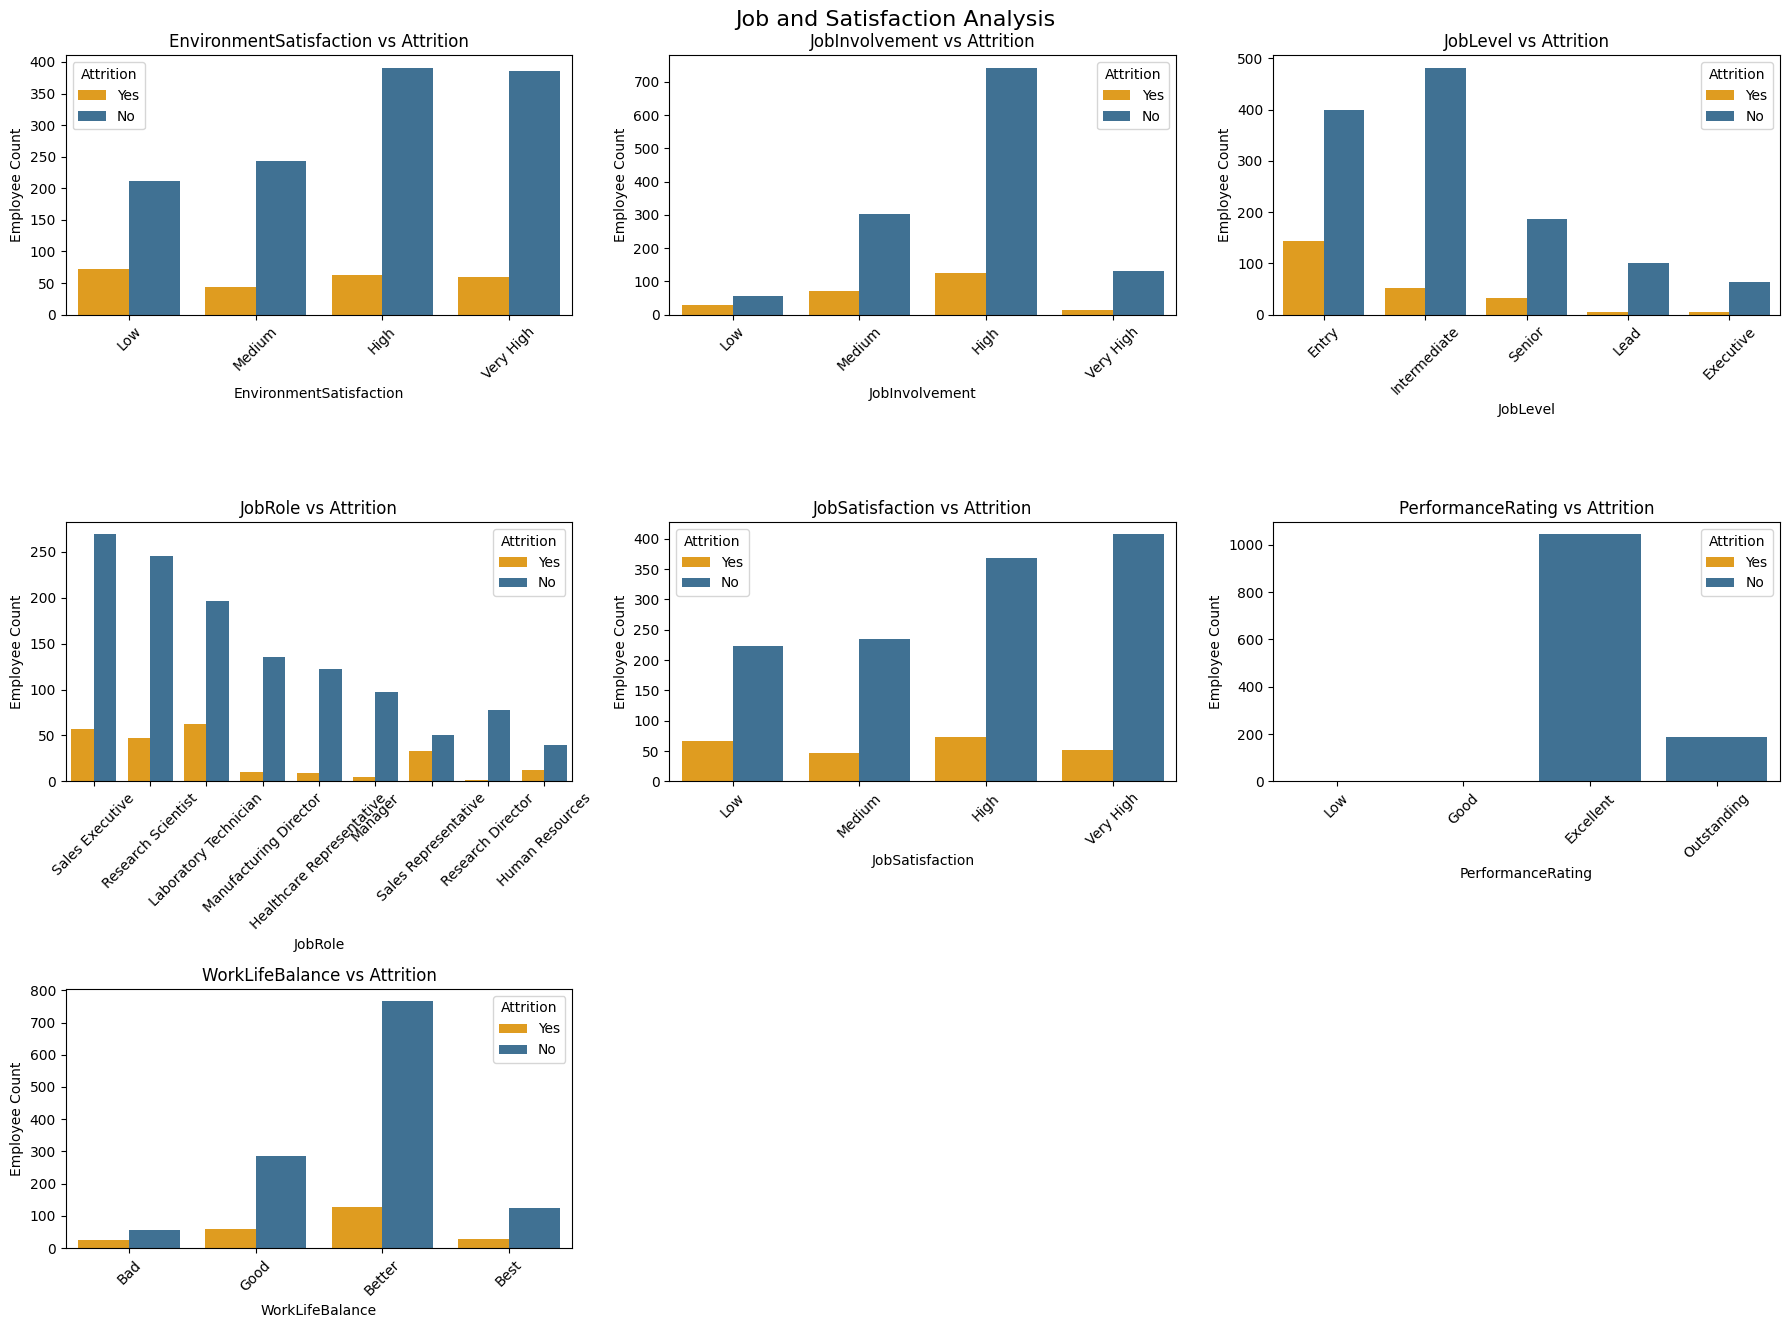

(<Figure size 1800x1350 with 7 Axes>,
 array([<Axes: title={'center': 'EnvironmentSatisfaction vs Attrition'}, xlabel='EnvironmentSatisfaction', ylabel='Employee Count'>,
        <Axes: title={'center': 'JobInvolvement vs Attrition'}, xlabel='JobInvolvement', ylabel='Employee Count'>,
        <Axes: title={'center': 'JobLevel vs Attrition'}, xlabel='JobLevel', ylabel='Employee Count'>,
        <Axes: title={'center': 'JobRole vs Attrition'}, xlabel='JobRole', ylabel='Employee Count'>,
        <Axes: title={'center': 'JobSatisfaction vs Attrition'}, xlabel='JobSatisfaction', ylabel='Employee Count'>,
        <Axes: title={'center': 'PerformanceRating vs Attrition'}, xlabel='PerformanceRating', ylabel='Employee Count'>,
        <Axes: title={'center': 'WorkLifeBalance vs Attrition'}, xlabel='WorkLifeBalance', ylabel='Employee Count'>,
        <Axes: >, <Axes: >], dtype=object))

In [39]:
plot_category(df,column_groups,"Job and Satisfaction")


In [40]:
display_category_tables(df,column_groups,"Job and Satisfaction")



EnvironmentSatisfaction


,EnvironmentSatisfaction,No,Yes,Total,AttritionRate
0,Low,212,72,284,25.35
1,Medium,244,43,287,14.98
2,High,391,62,453,13.69
3,Very High,386,60,446,13.45



JobInvolvement


,JobInvolvement,No,Yes,Total,AttritionRate
0,Low,55,28,83,33.73
1,Medium,304,71,375,18.93
2,High,743,125,868,14.40
3,Very High,131,13,144,9.03



JobLevel


,JobLevel,No,Yes,Total,AttritionRate
0,Entry,400,143,543,26.34
1,Intermediate,482,52,534,9.74
2,Senior,186,32,218,14.68
3,Lead,101,5,106,4.72
4,Executive,64,5,69,7.25


... (4 outputs left out)


PerformanceRating


,PerformanceRating,No,Yes,Total,AttritionRate
0,Excellent,1044,200,1244,16.08
1,Outstanding,189,37,226,16.37



WorkLifeBalance


,WorkLifeBalance,No,Yes,Total,AttritionRate
0,Bad,55,25,80,31.25
1,Good,286,58,344,16.86
2,Better,766,127,893,14.22
3,Best,126,27,153,17.65


### Work Conditions

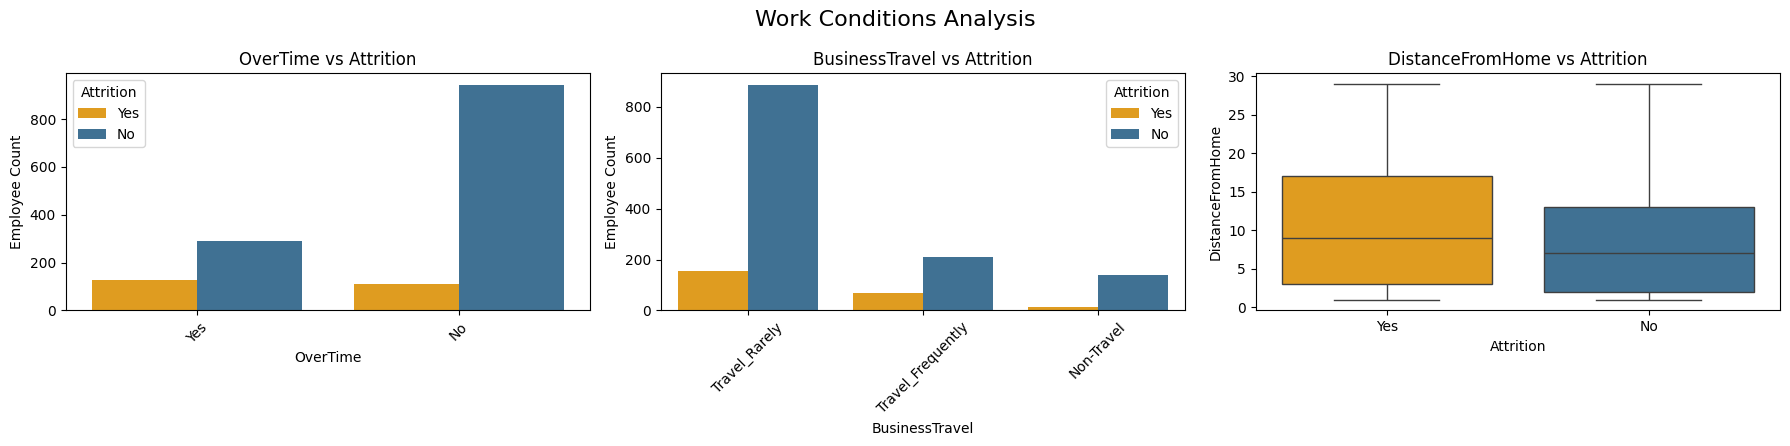

(<Figure size 1800x450 with 3 Axes>,
 array([<Axes: title={'center': 'OverTime vs Attrition'}, xlabel='OverTime', ylabel='Employee Count'>,
        <Axes: title={'center': 'BusinessTravel vs Attrition'}, xlabel='BusinessTravel', ylabel='Employee Count'>,
        <Axes: title={'center': 'DistanceFromHome vs Attrition'}, xlabel='Attrition', ylabel='DistanceFromHome'>],
       dtype=object))

In [41]:
plot_category(df,column_groups,"Work Conditions")


- attretion ratio with over time is higher , we have association

### Organization

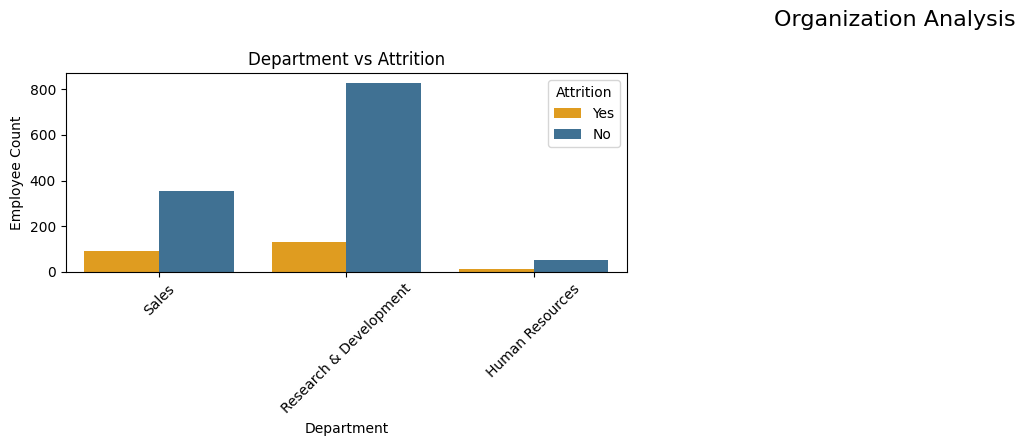

(<Figure size 1800x450 with 1 Axes>,
 array([<Axes: title={'center': 'Department vs Attrition'}, xlabel='Department', ylabel='Employee Count'>,
        <Axes: >, <Axes: >], dtype=object))

In [42]:
plot_category(df,column_groups,"Organization")


seems there is no association between department and attrition

# Numerical Columns Distruibutions

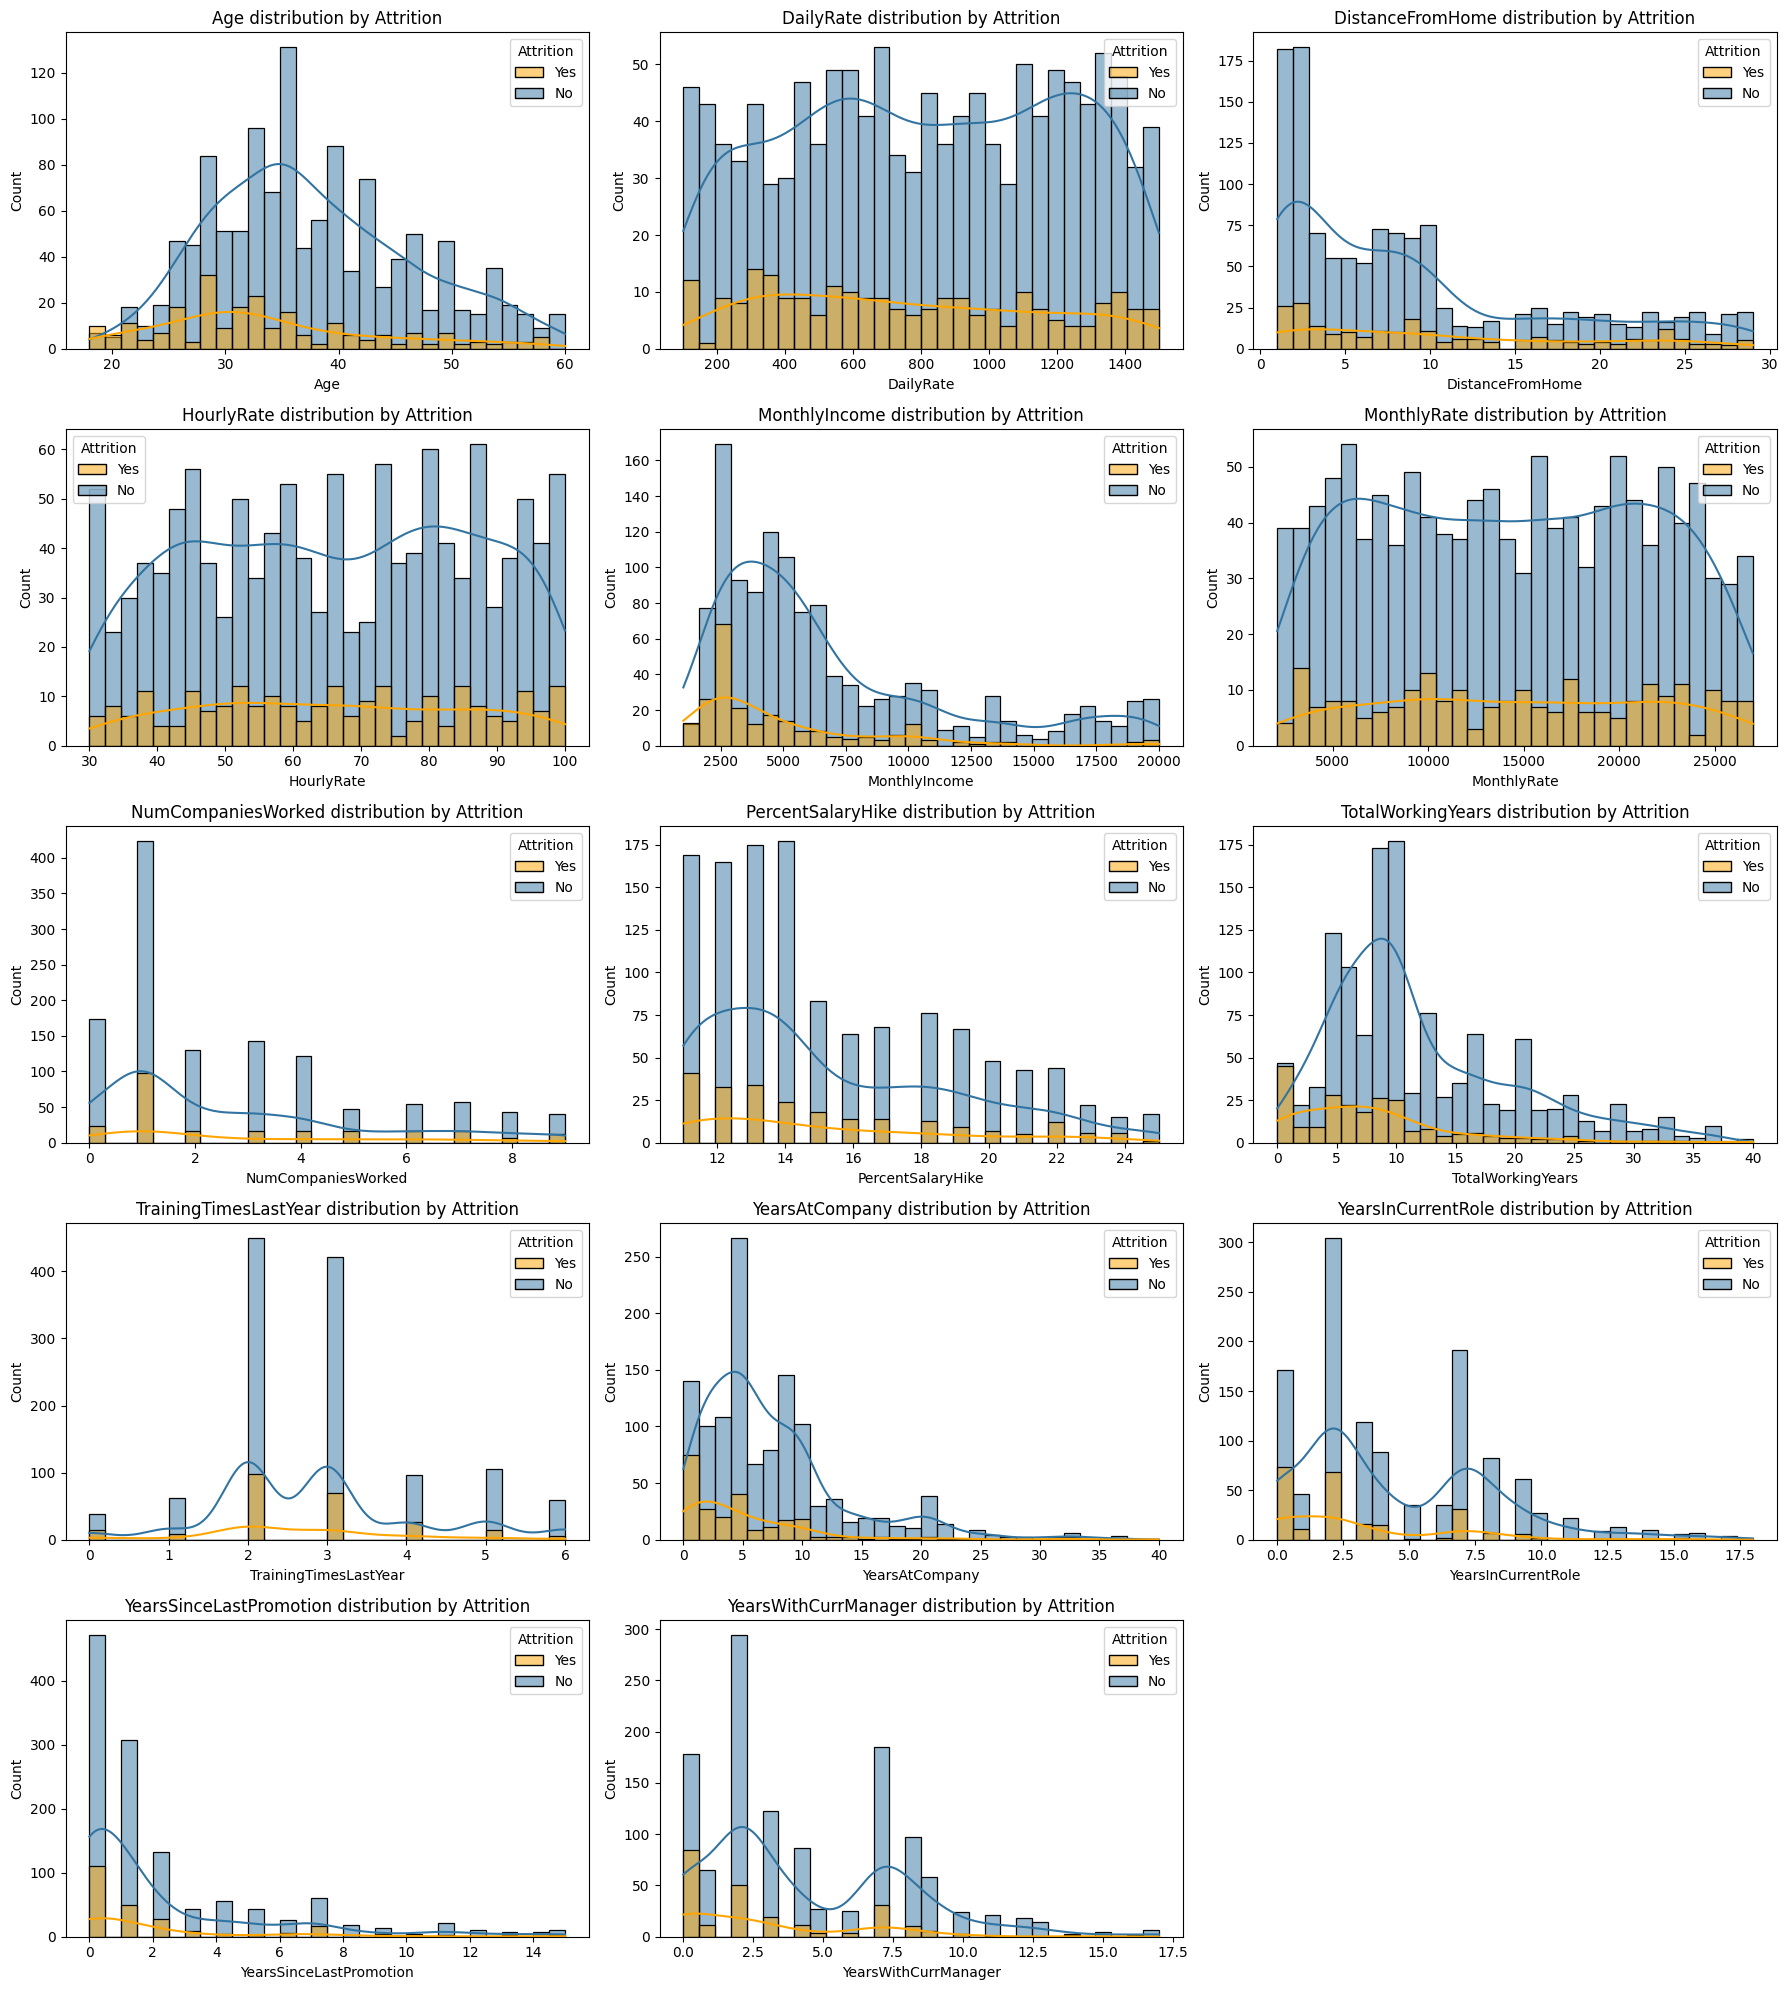

In [43]:
n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Attrition",
        multiple="layer",
        bins=30,
        
        ax=axes[idx],
        kde=True,
        palette=color_map
    )
    axes[idx].set_title(f"{col} distribution by Attrition")

# Remove empty plots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

the useful info that i found from the distributions that monthly income is right skewd, which says the same we said above 

# #TODO Continue from here 

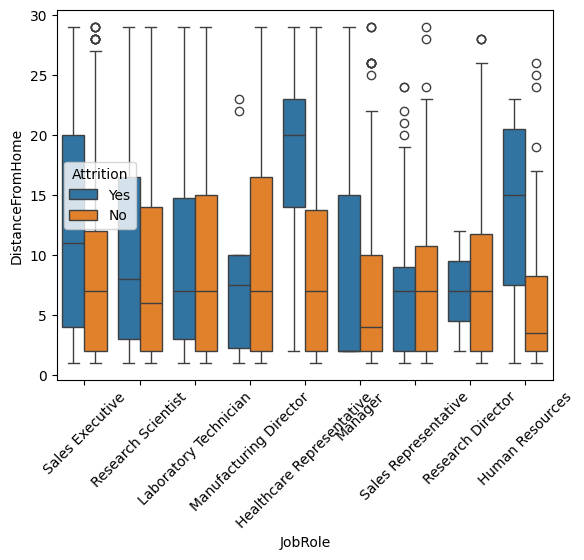

In [44]:
sns.boxplot(
    data=df,
    x="JobRole",
    y="DistanceFromHome",
    hue="Attrition"
)
plt.xticks(rotation=45)
plt.show()

In [49]:
doctor = df[df["Education"]=='Doctor']

doctor.groupby("Attrition")[["DailyRate", "HourlyRate", "MonthlyIncome"]].agg(
    ["count", "mean", "median"]
).round(1)

DailyRate               HourlyRate              MonthlyIncome  \
              count   mean median      count  mean median         count   
Attrition                                                                 
No               43  777.6  796.0         43  66.3   71.0            43   
Yes               5  855.0  607.0          5  86.8   89.0             5   

                           
             mean  median  
Attrition                  
No         8559.9  6272.0  
Yes        5850.2  6134.0

Observations About crossing between categorical and numerical columns: 
- Business Travel : nothing important from the plots
- Department : 
  - ages of HR employees who left are smaller than those who stayed in general, also distance from home for those who left is higher than those who stayed
  - most of the leaving people from HR department and from Reserach & Development deapramnt has lower monthly income than those who stayed 
  - in general, people who left from the 3 department has lower total working years & years at the company than those who stayed

- Education Degree : 
  - in all fileds, the monthly income for leavers is less than who stayed

- Education Field: 
  - same stuff, high distance from home for HR emploees and lower ages in general
  - Low Monthly Income for leavers
  - lower working years for HR edu fileds

- Environmnet Satisfaction : Nothing
- Gender : Nothing, very similiar charts
- Job Envolvment : Very similiar charts
- Job Level : who left with level " Lead " has lower monthly income than the others in the same Job level, also who are in lead and higher , have more than 20 years at the company
- Job Role :

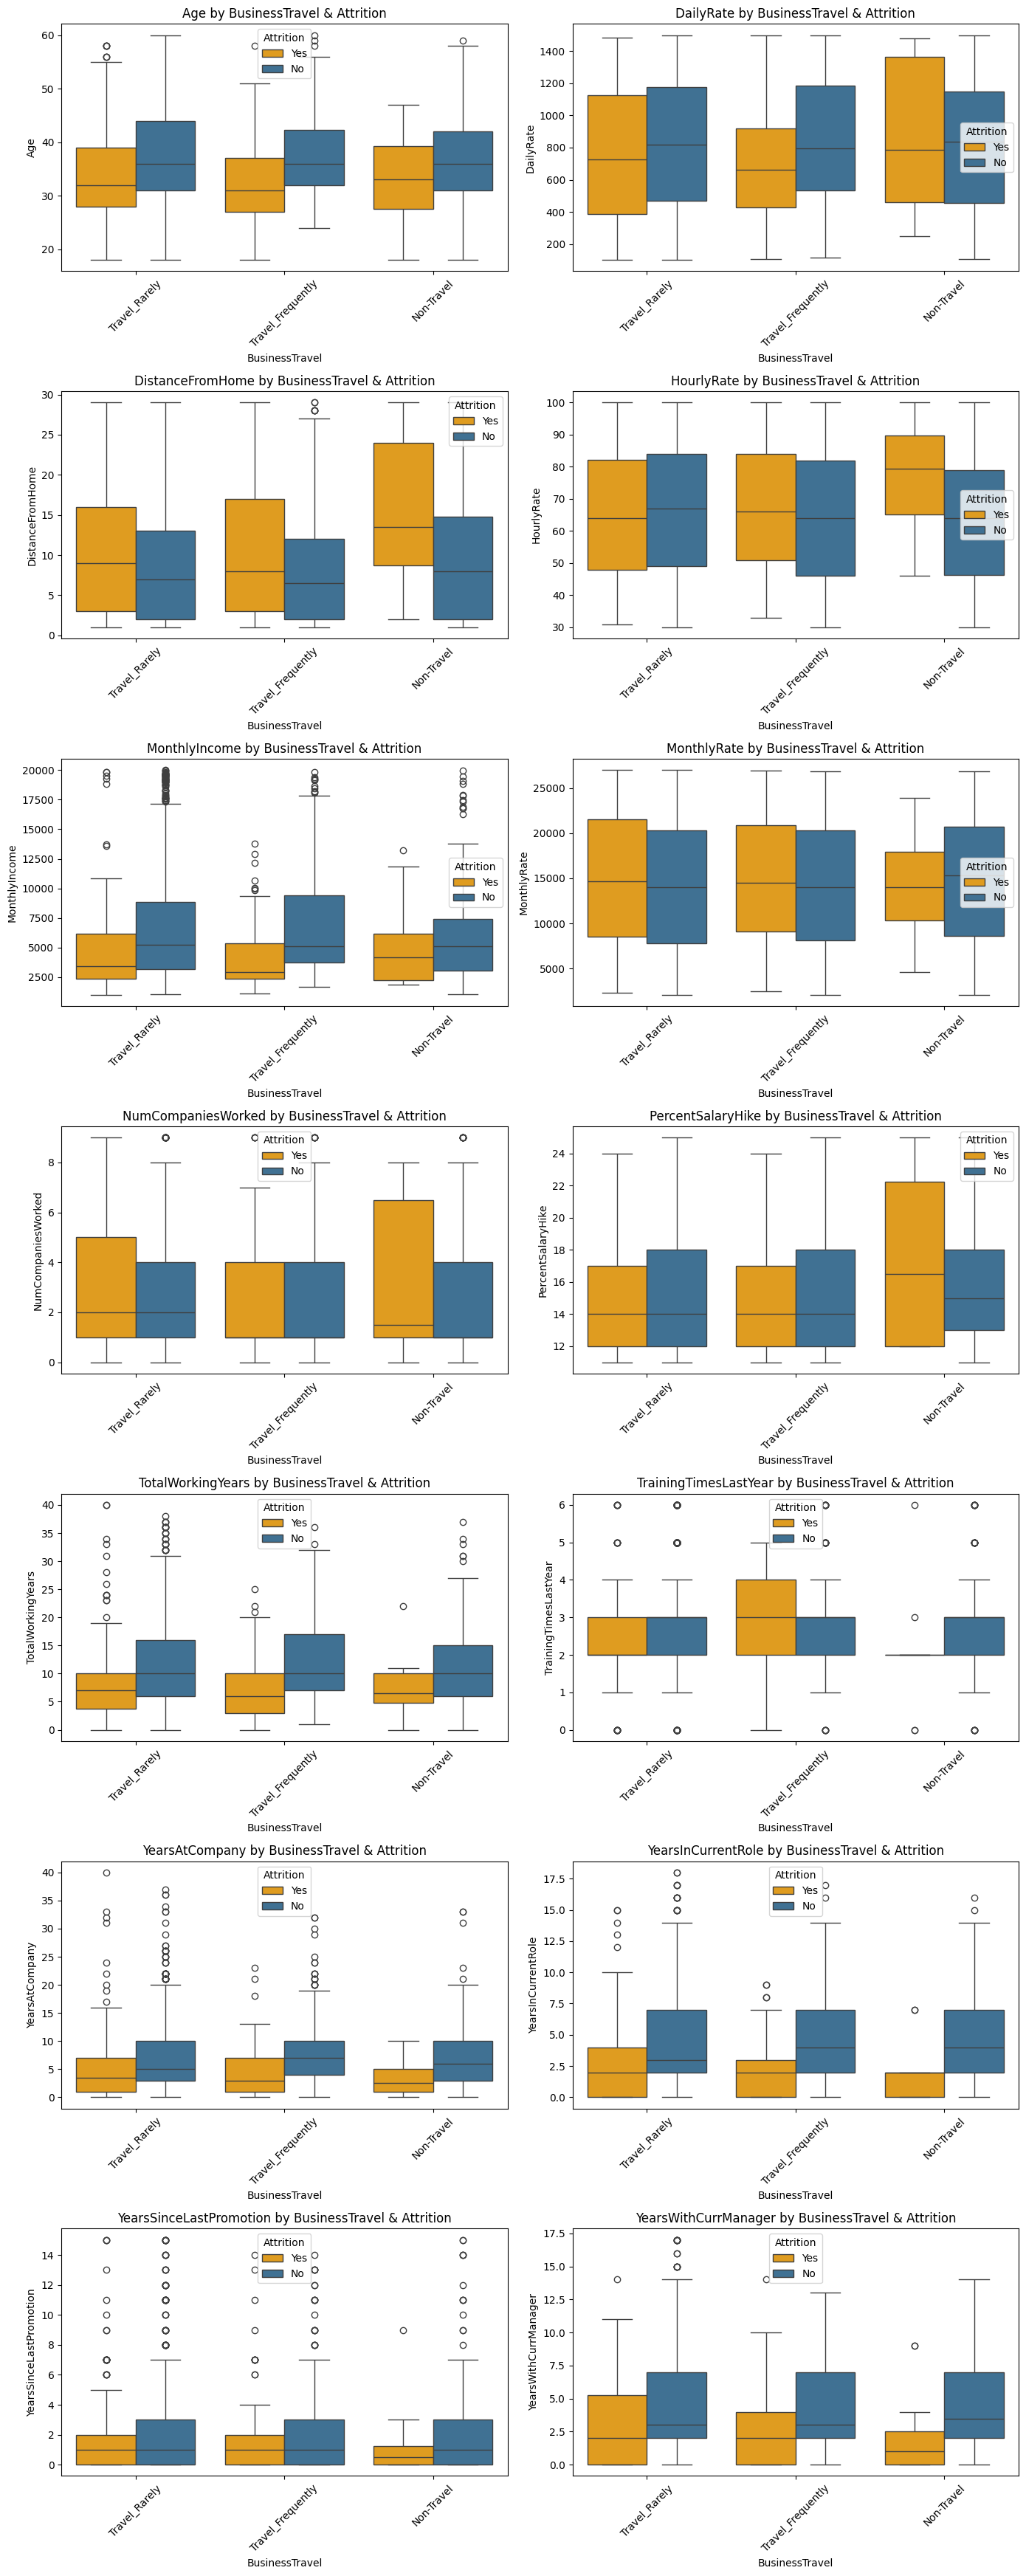

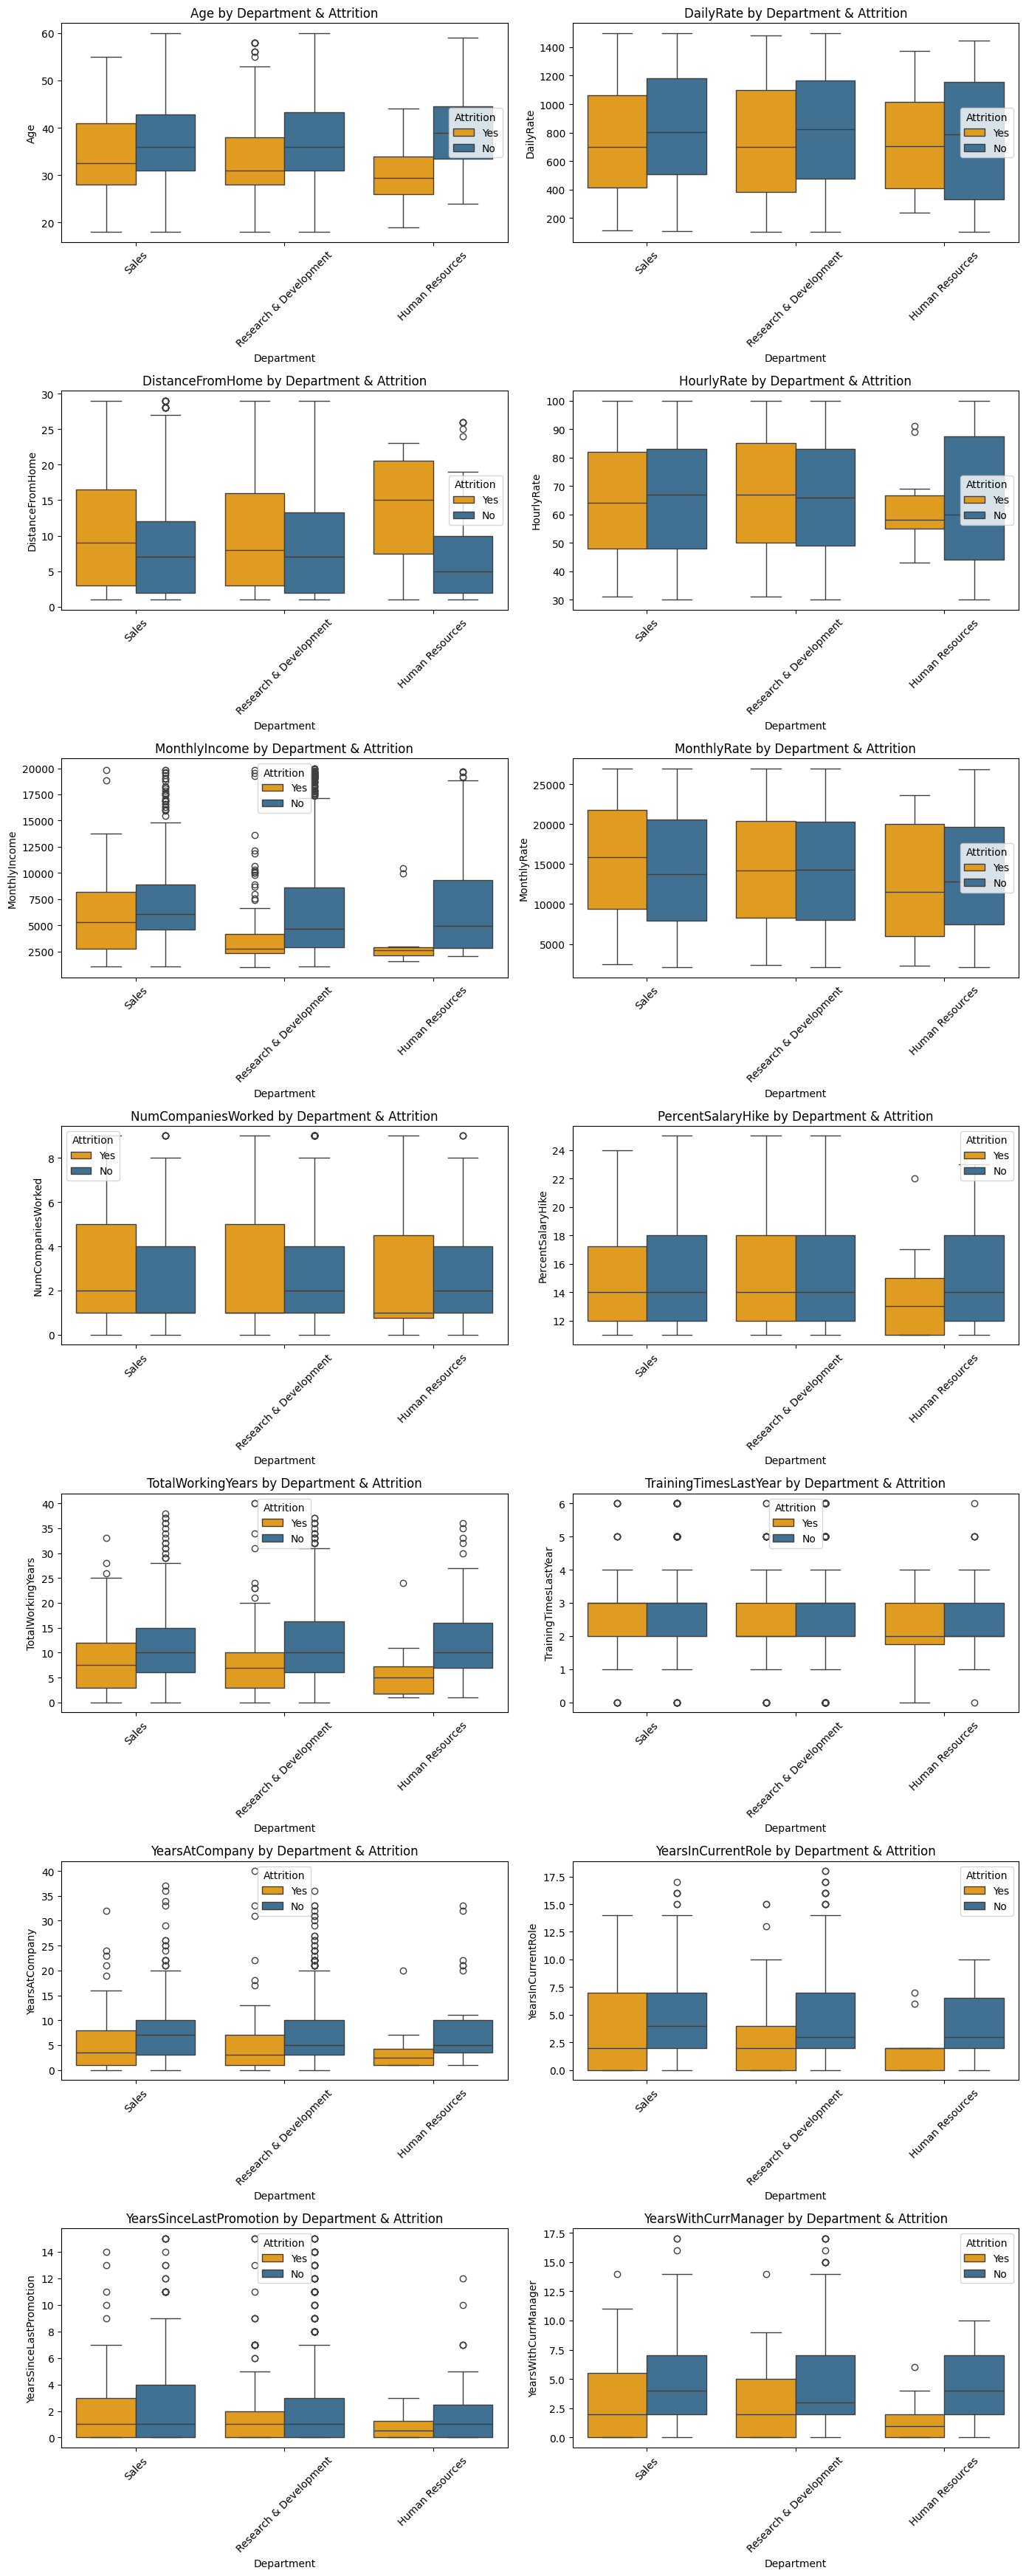

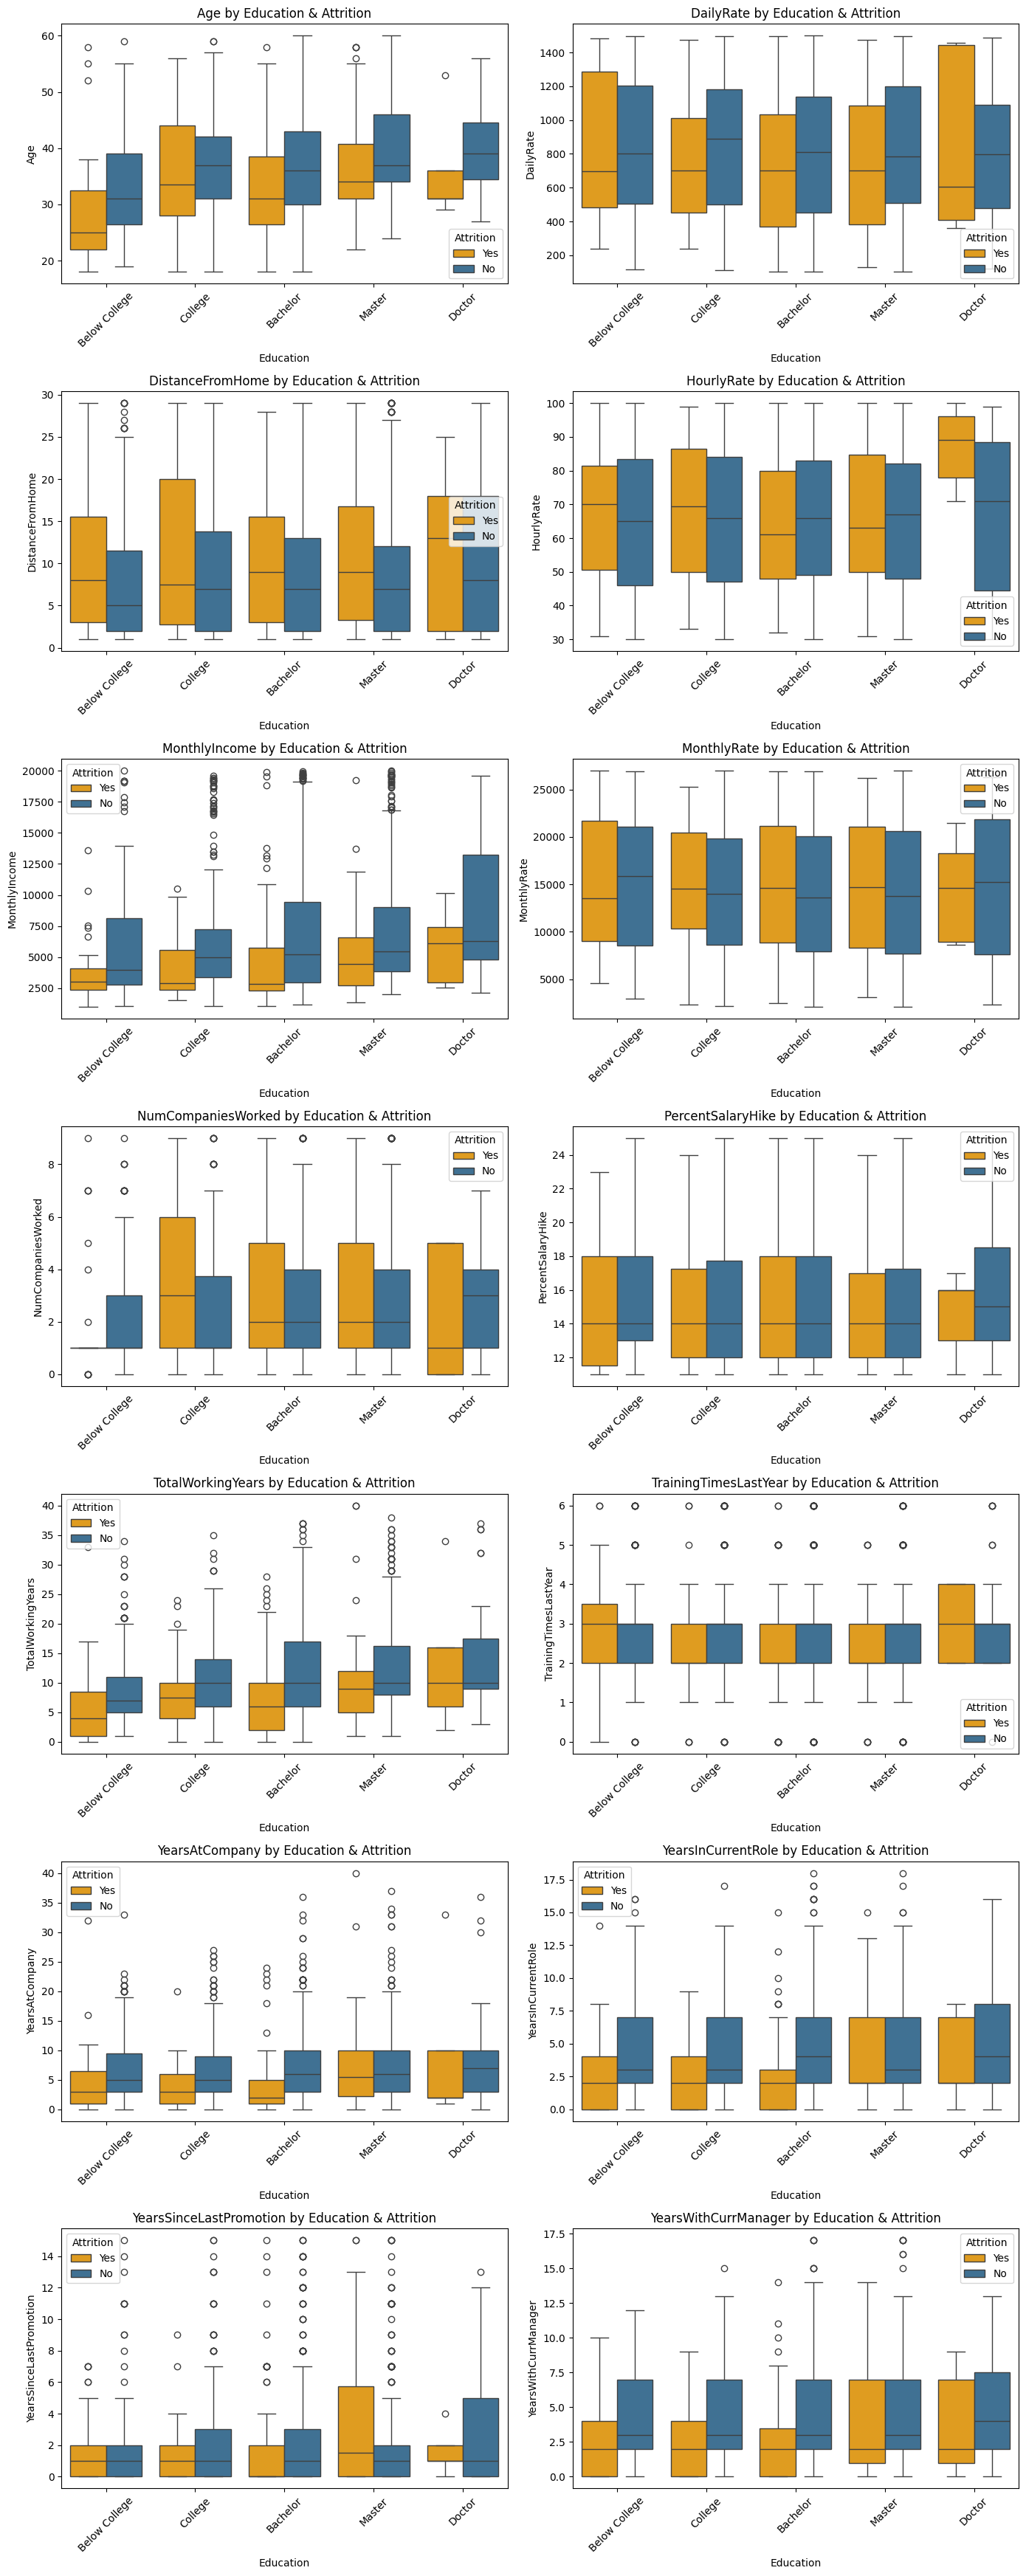

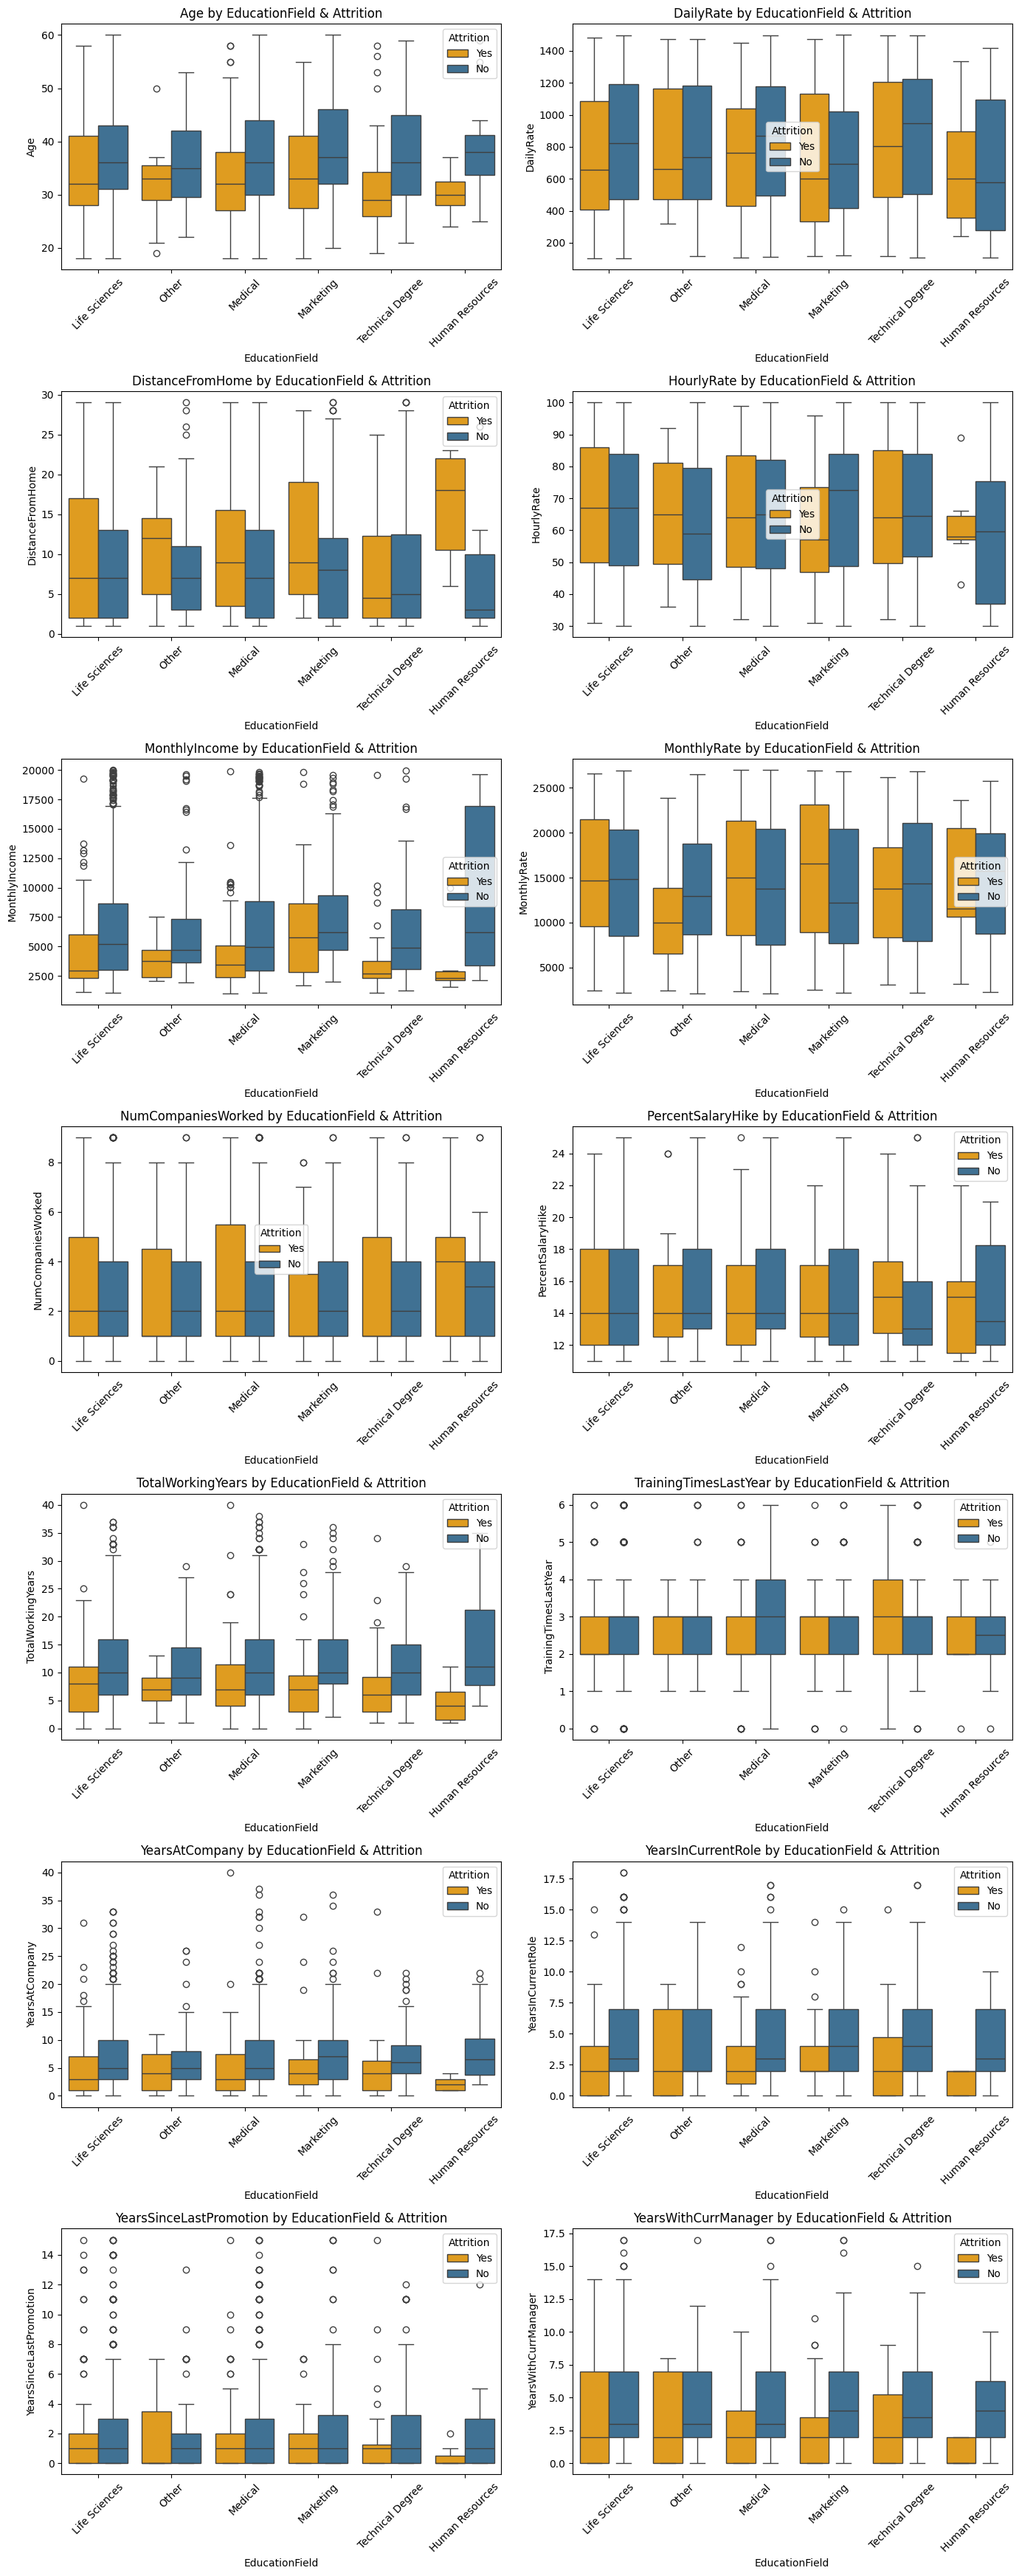

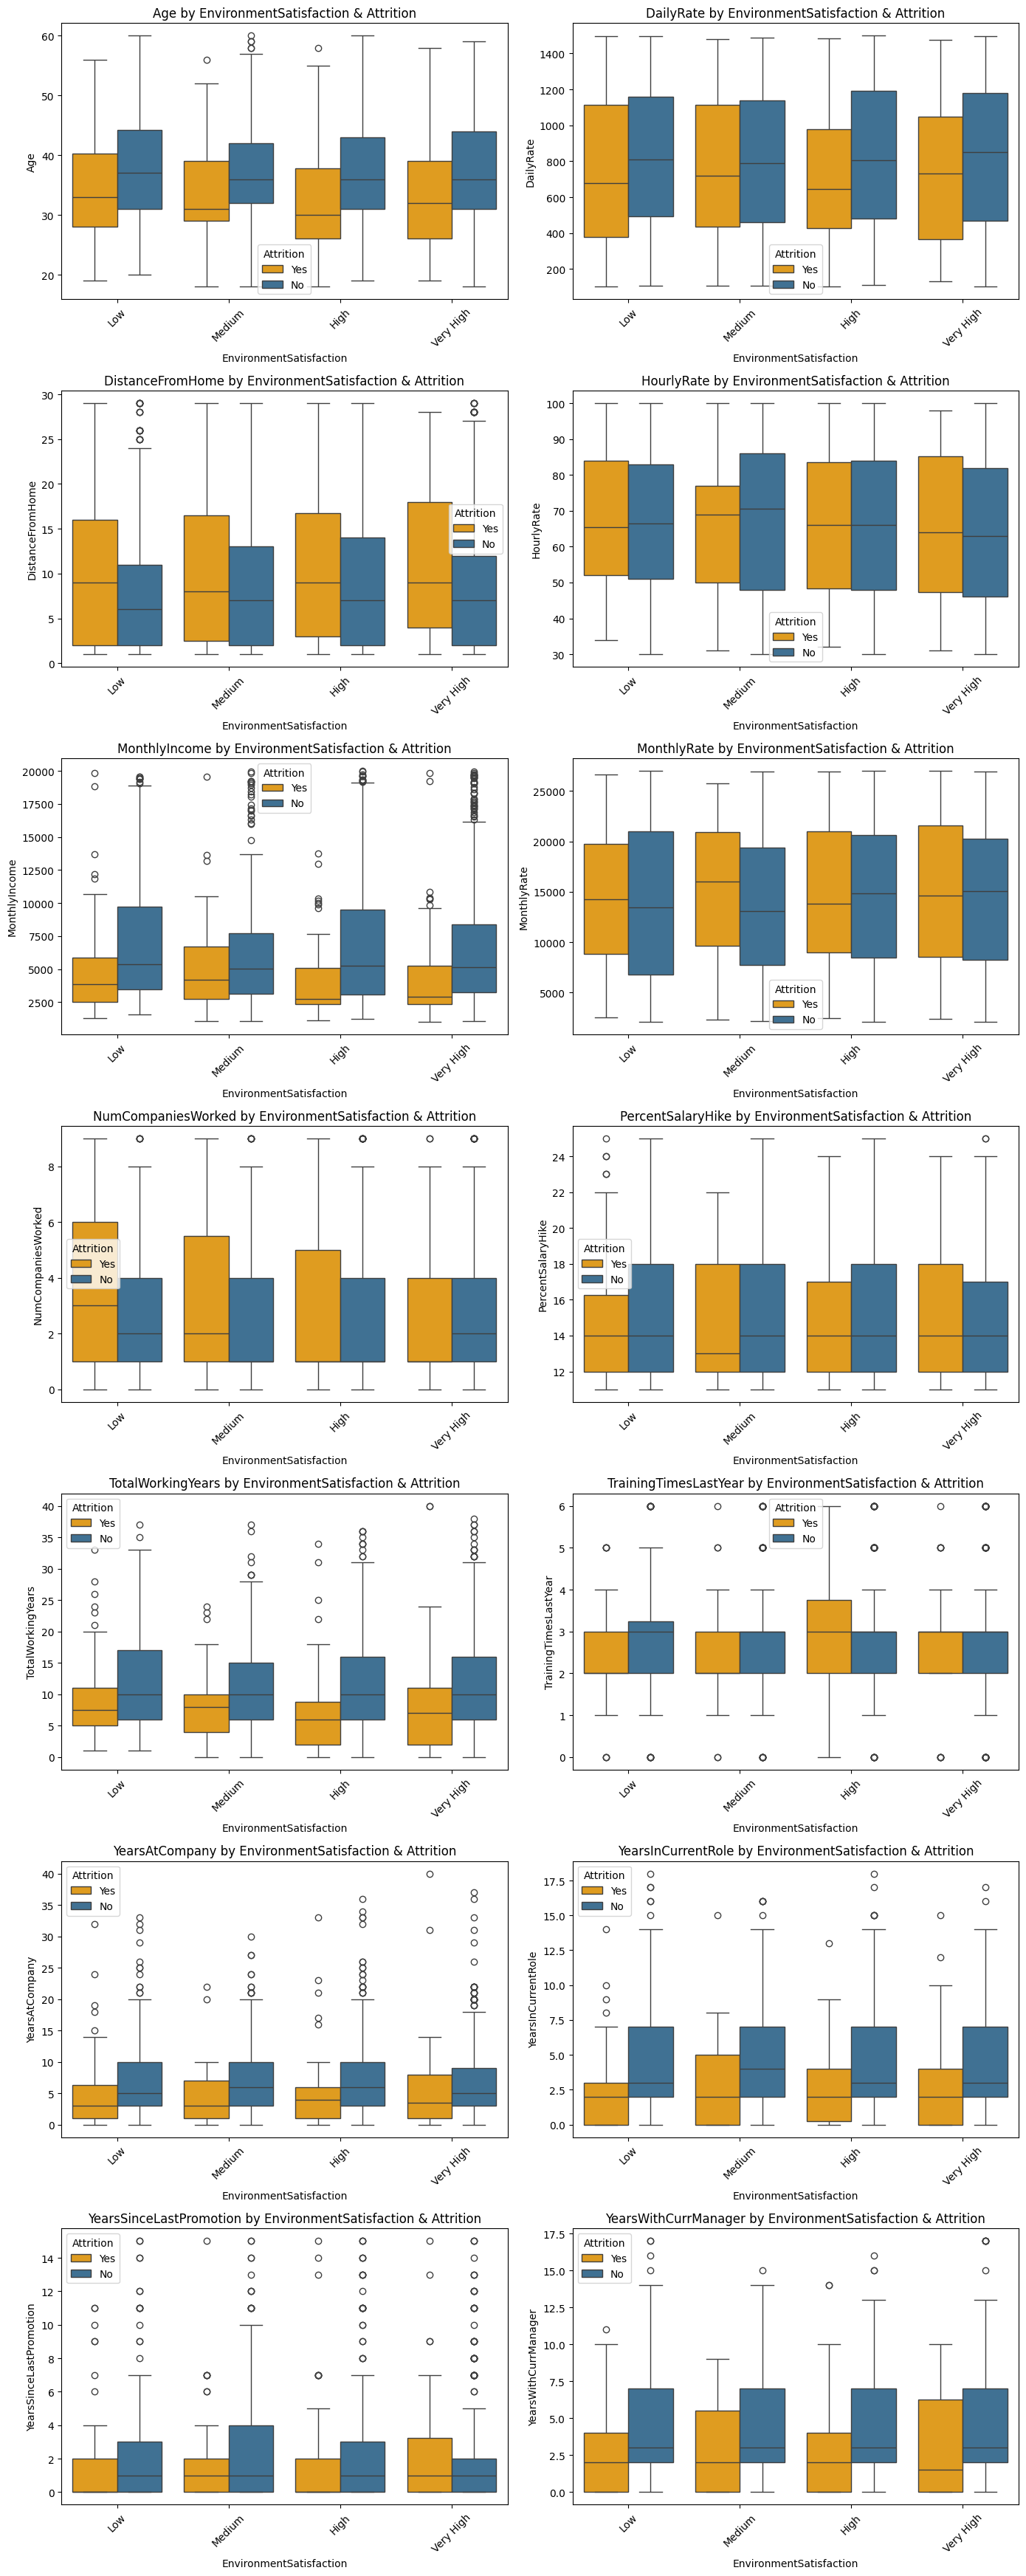

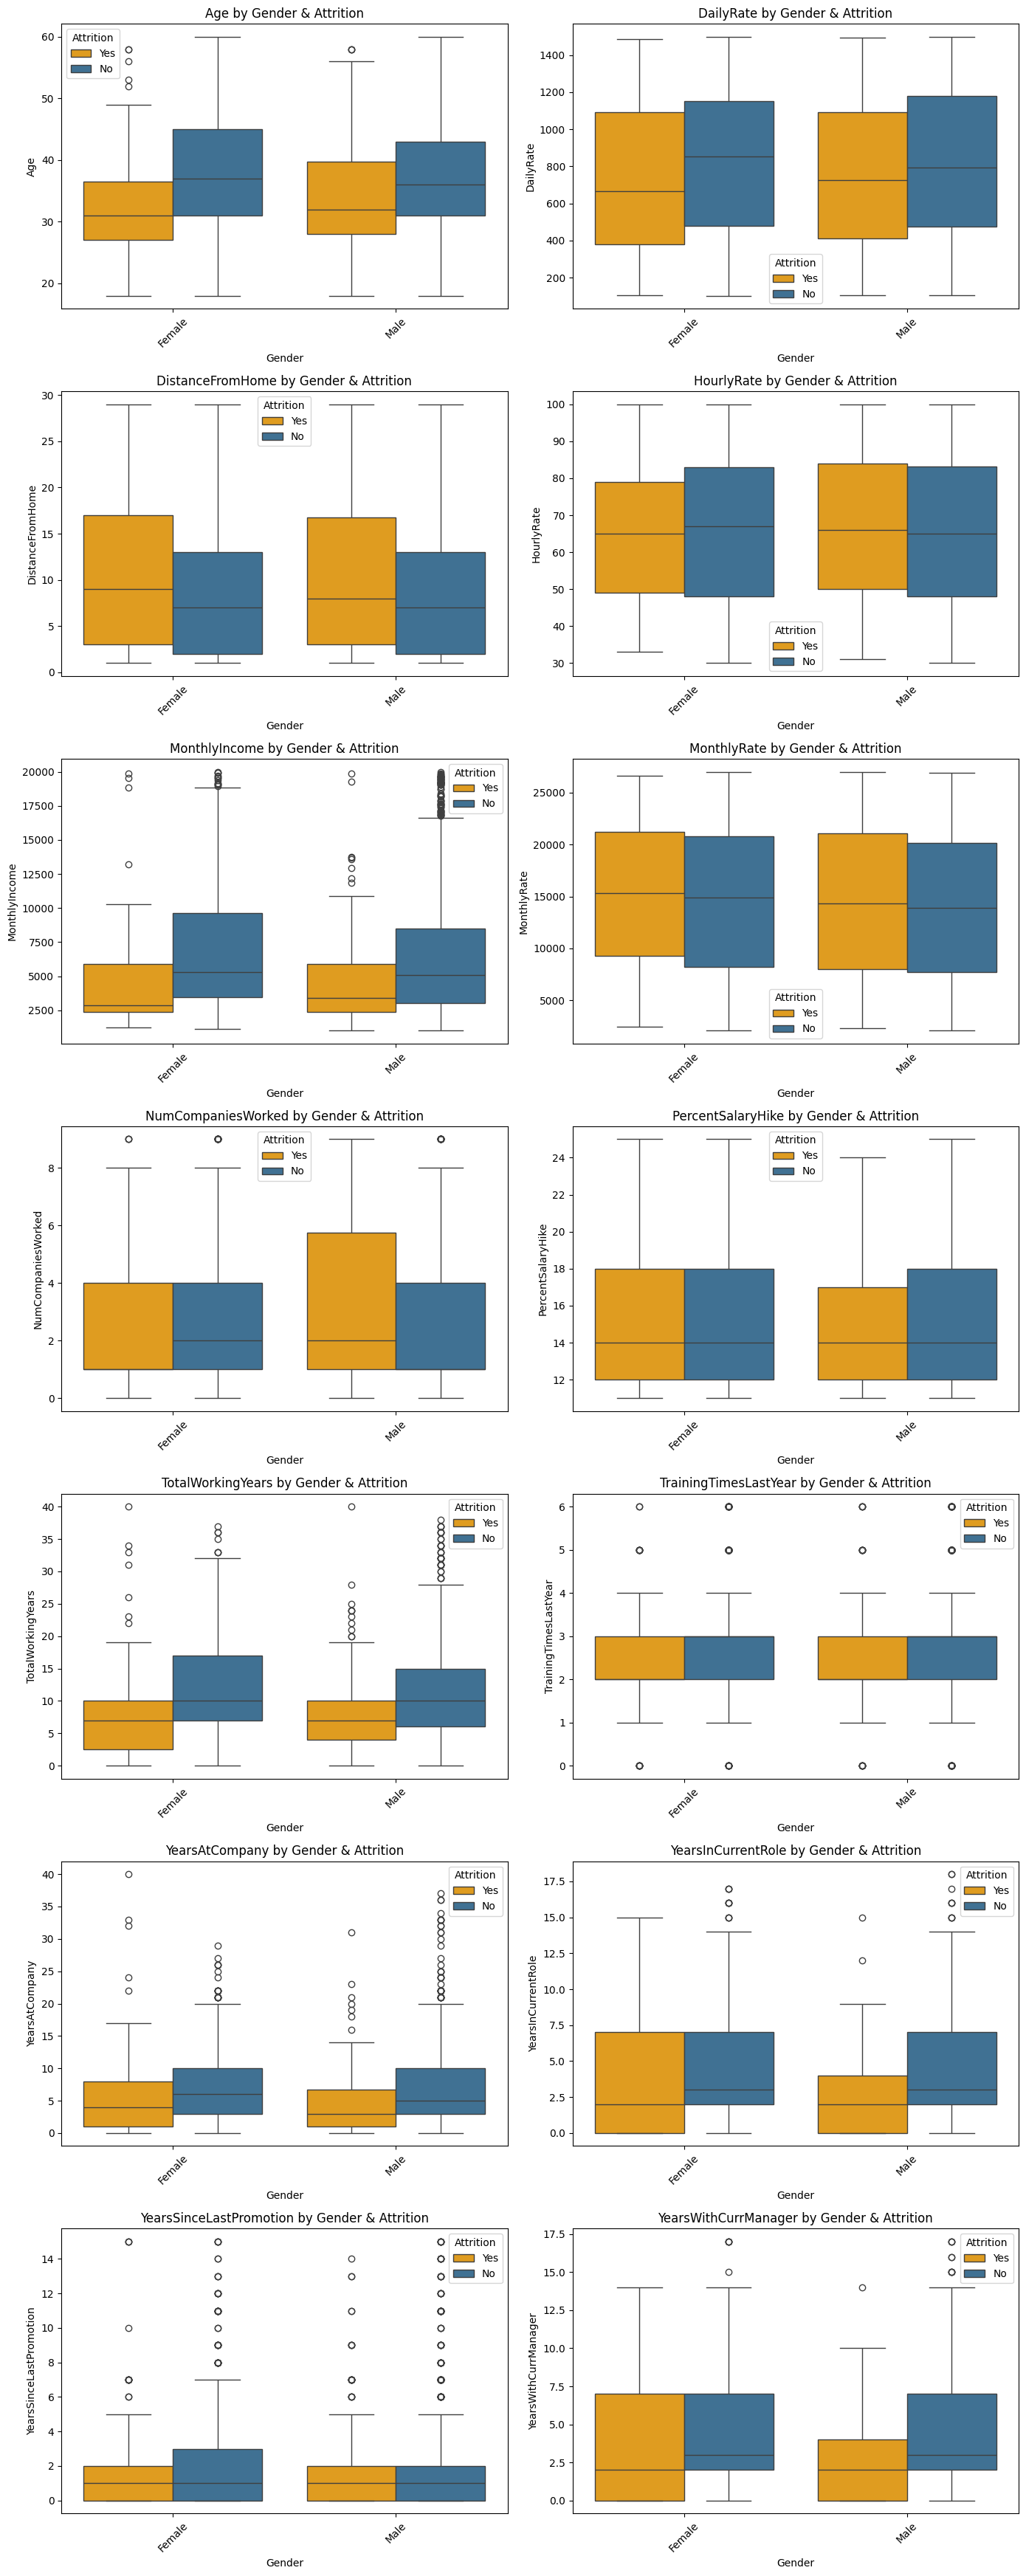

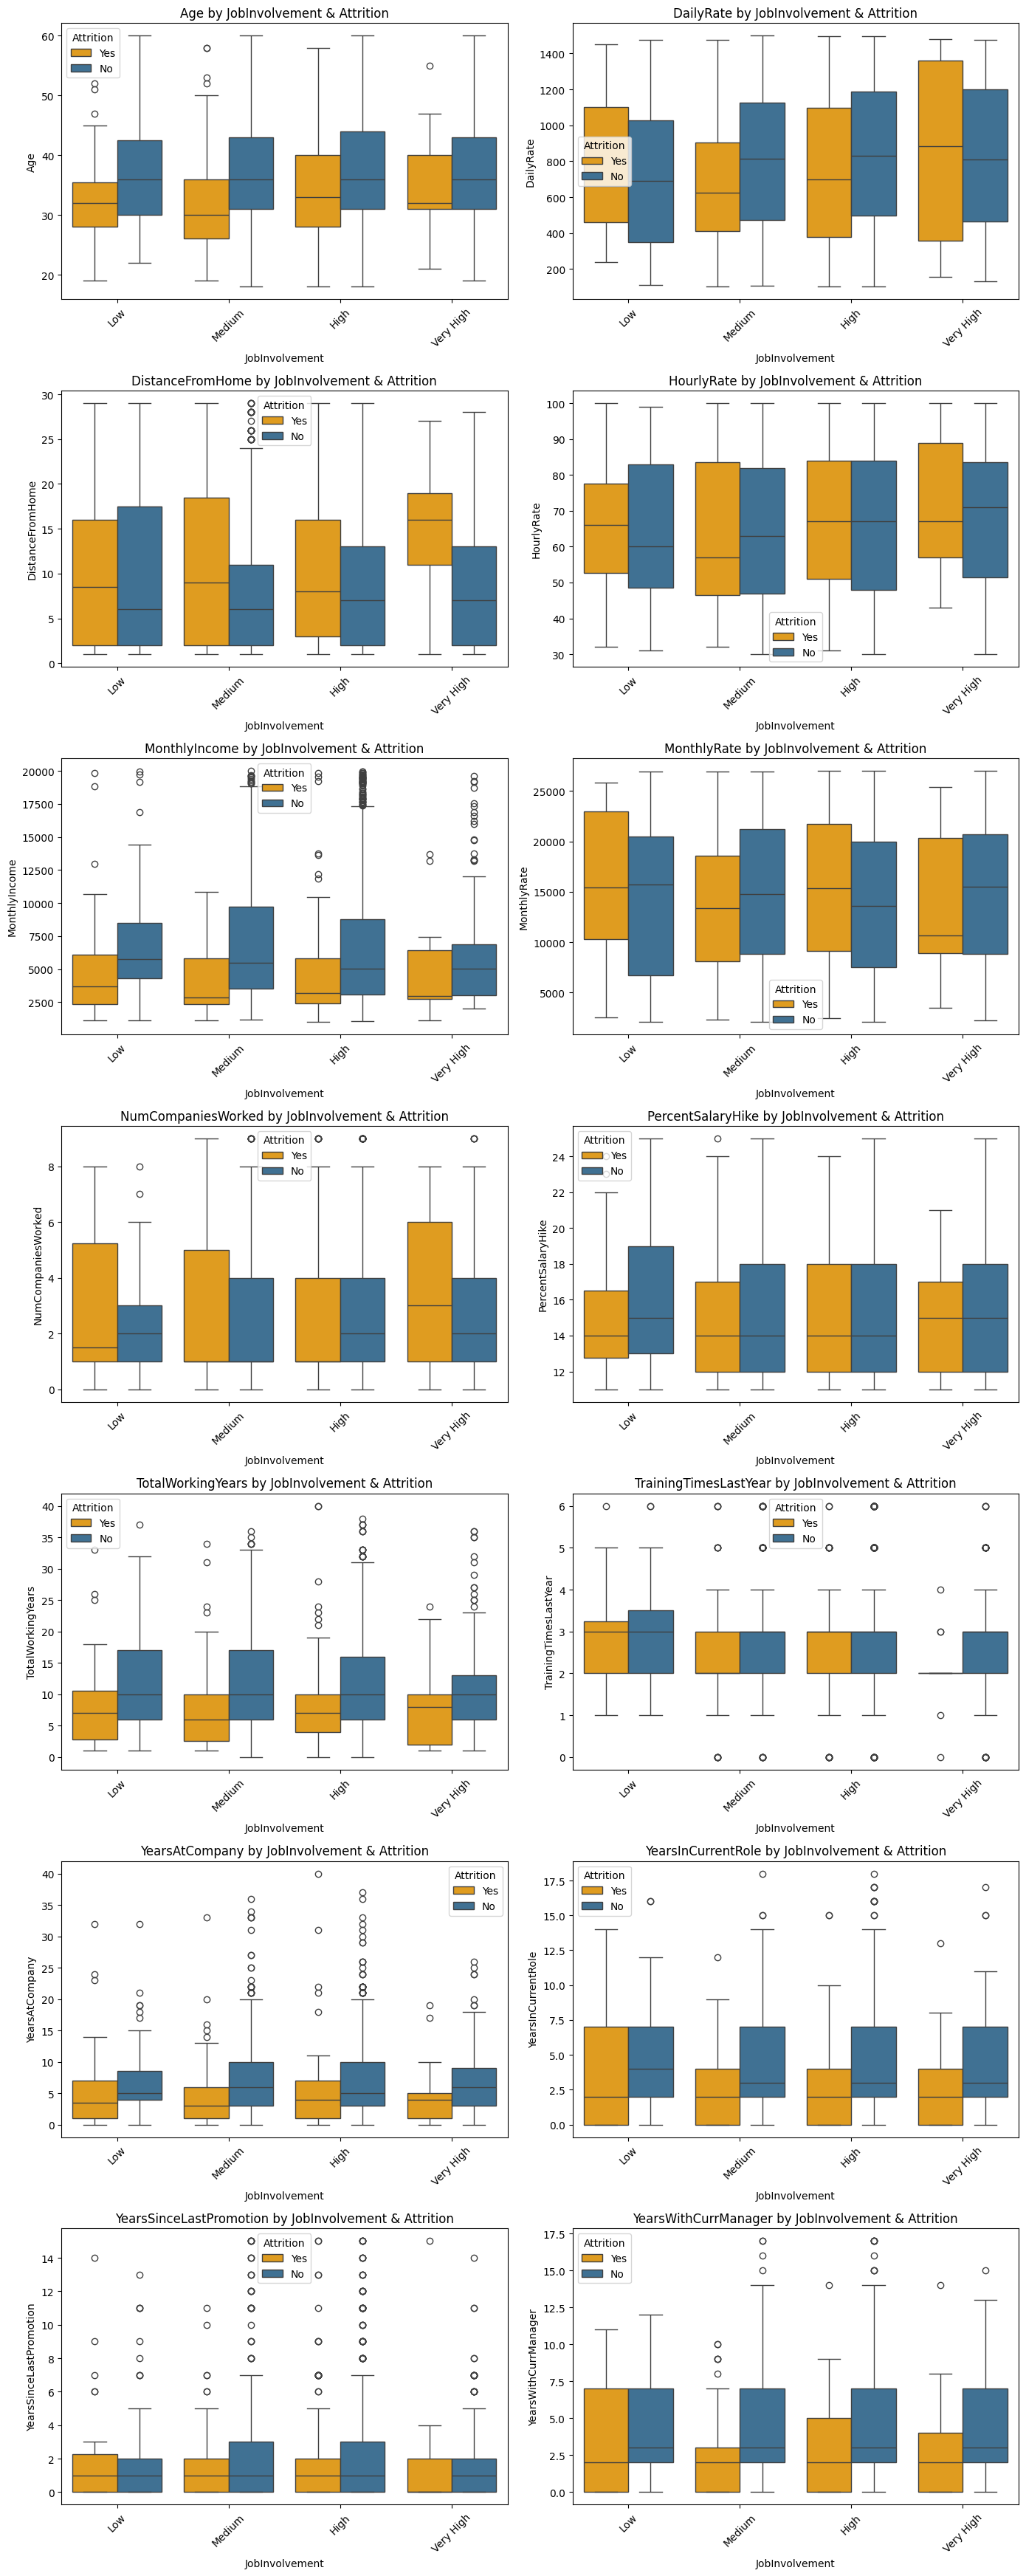

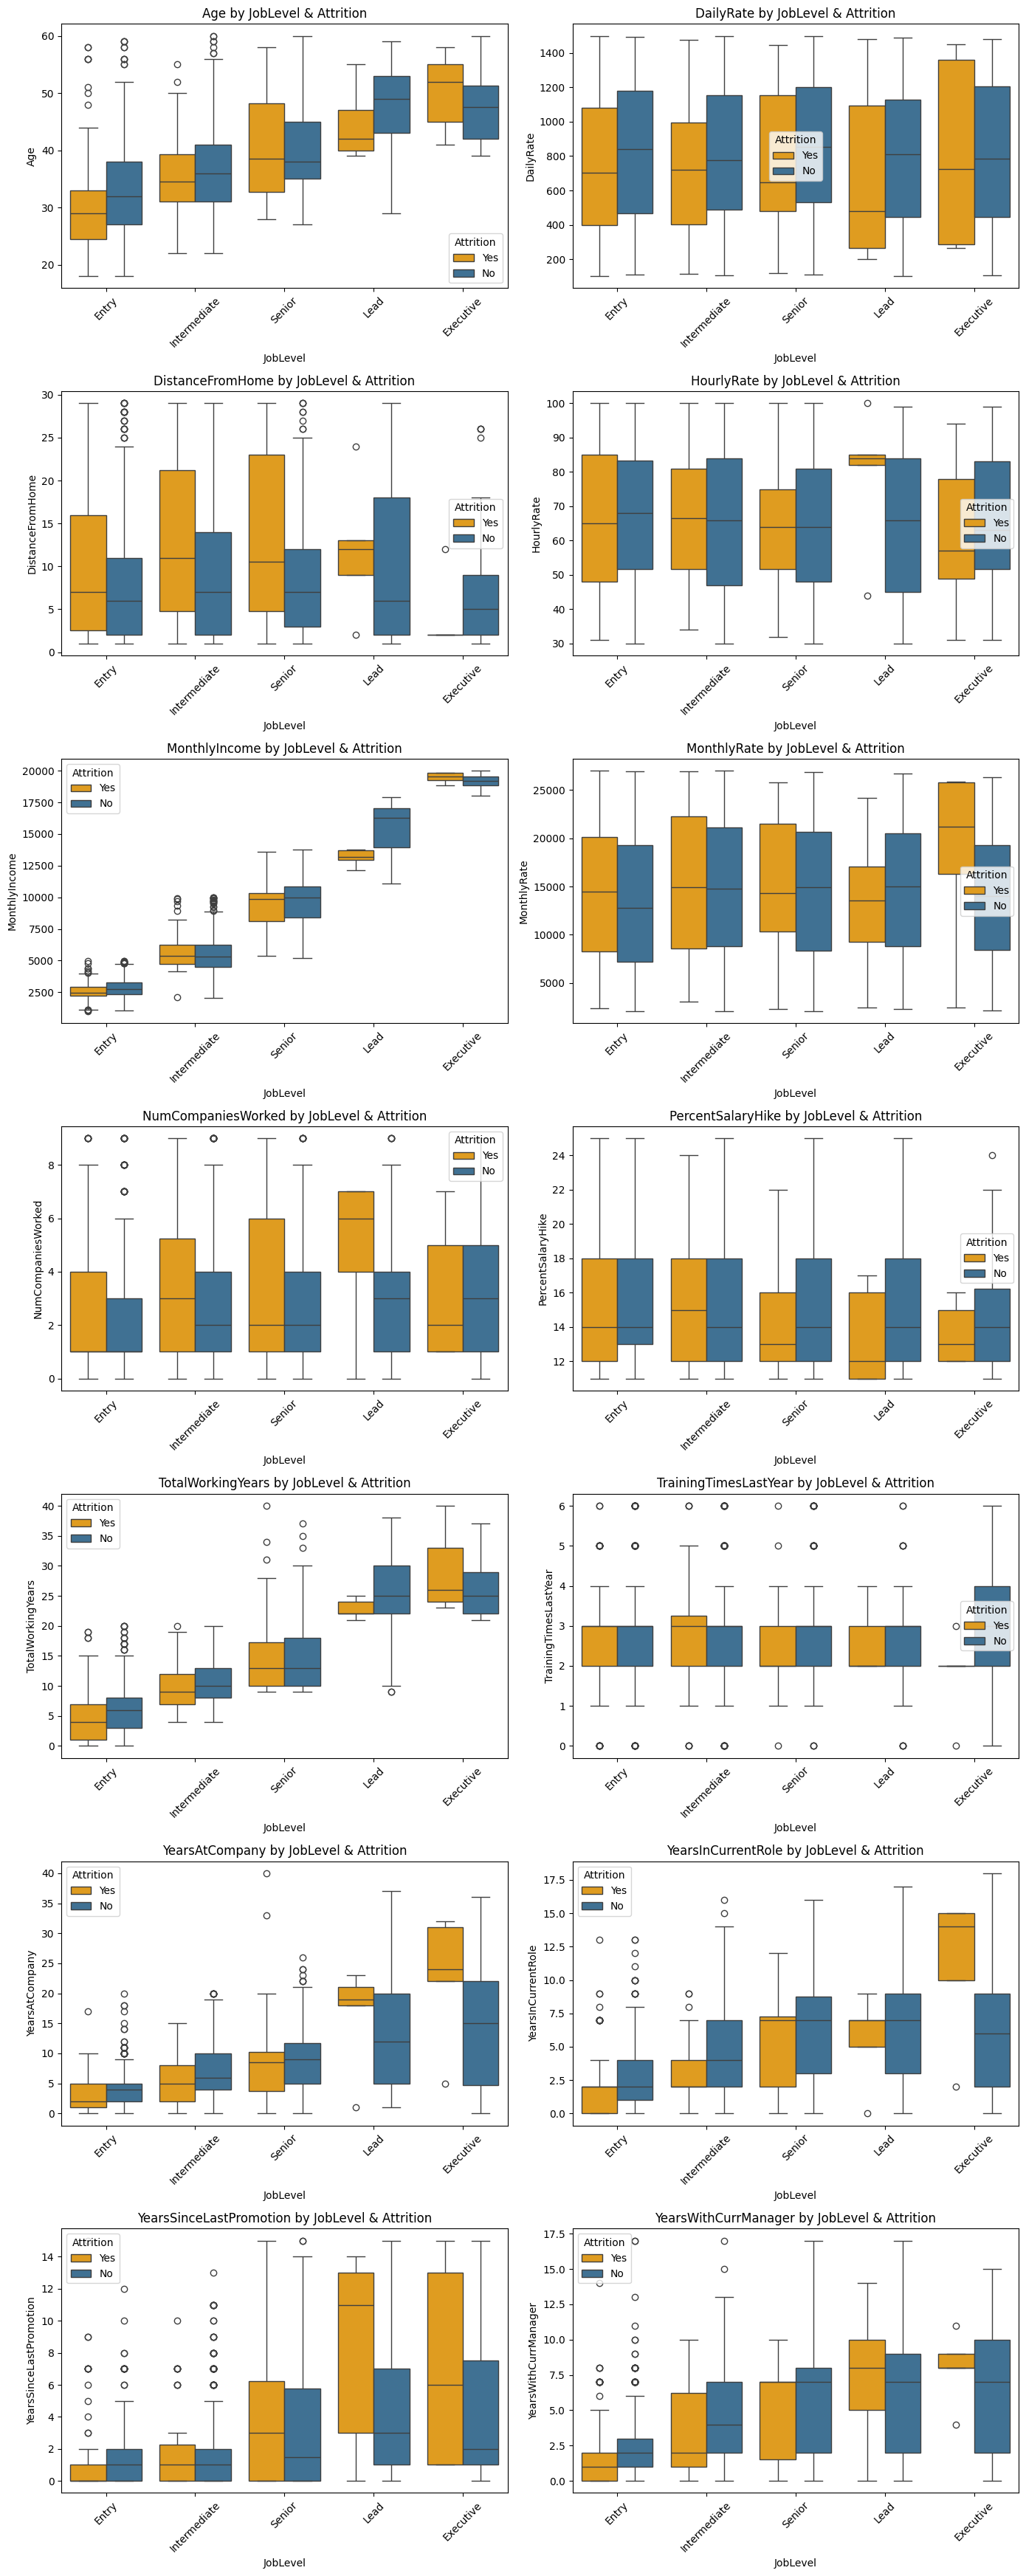

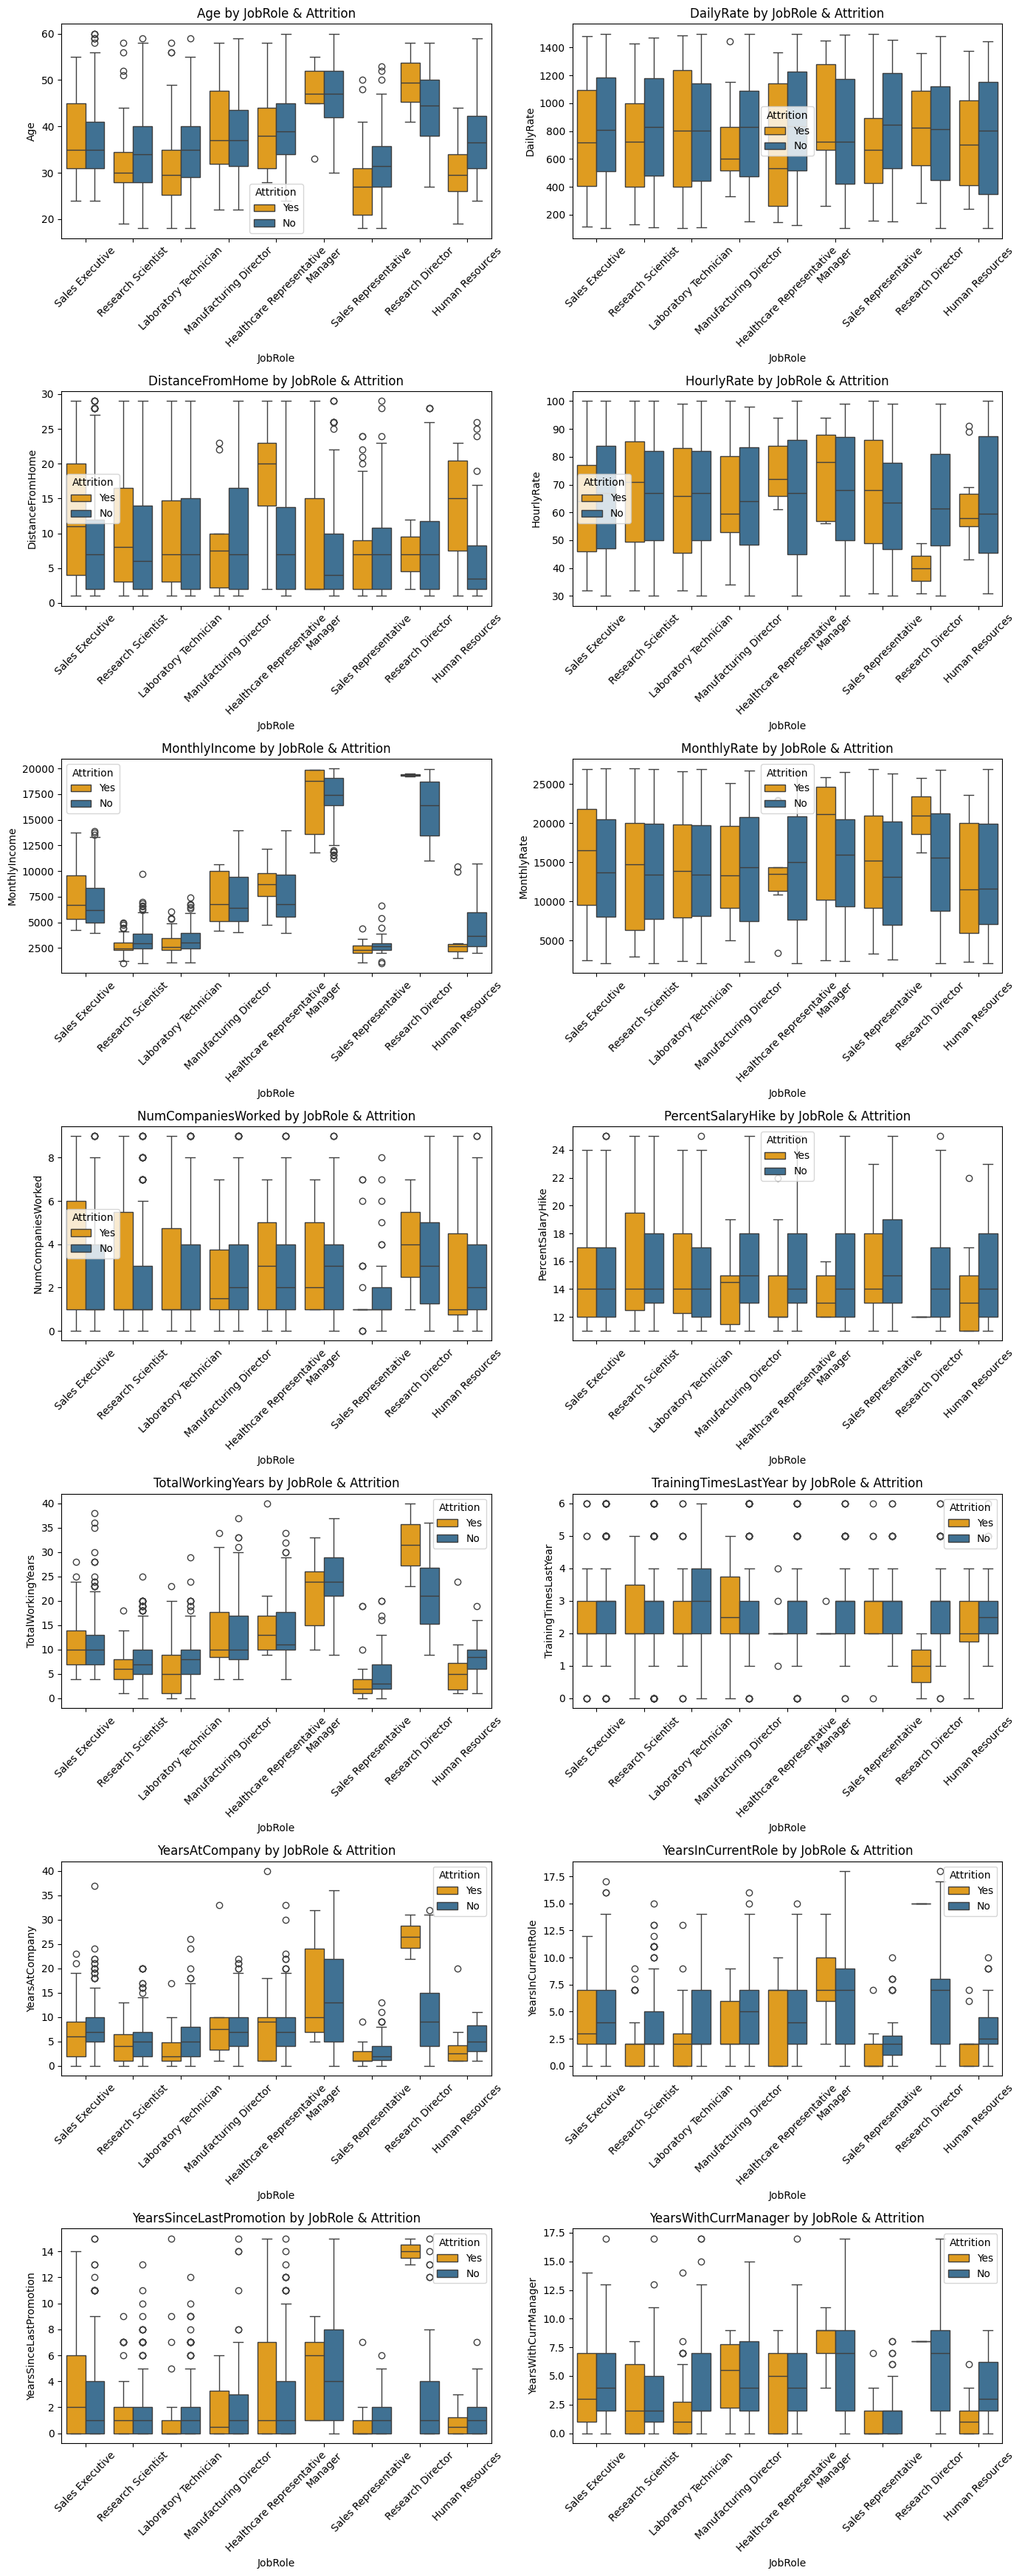

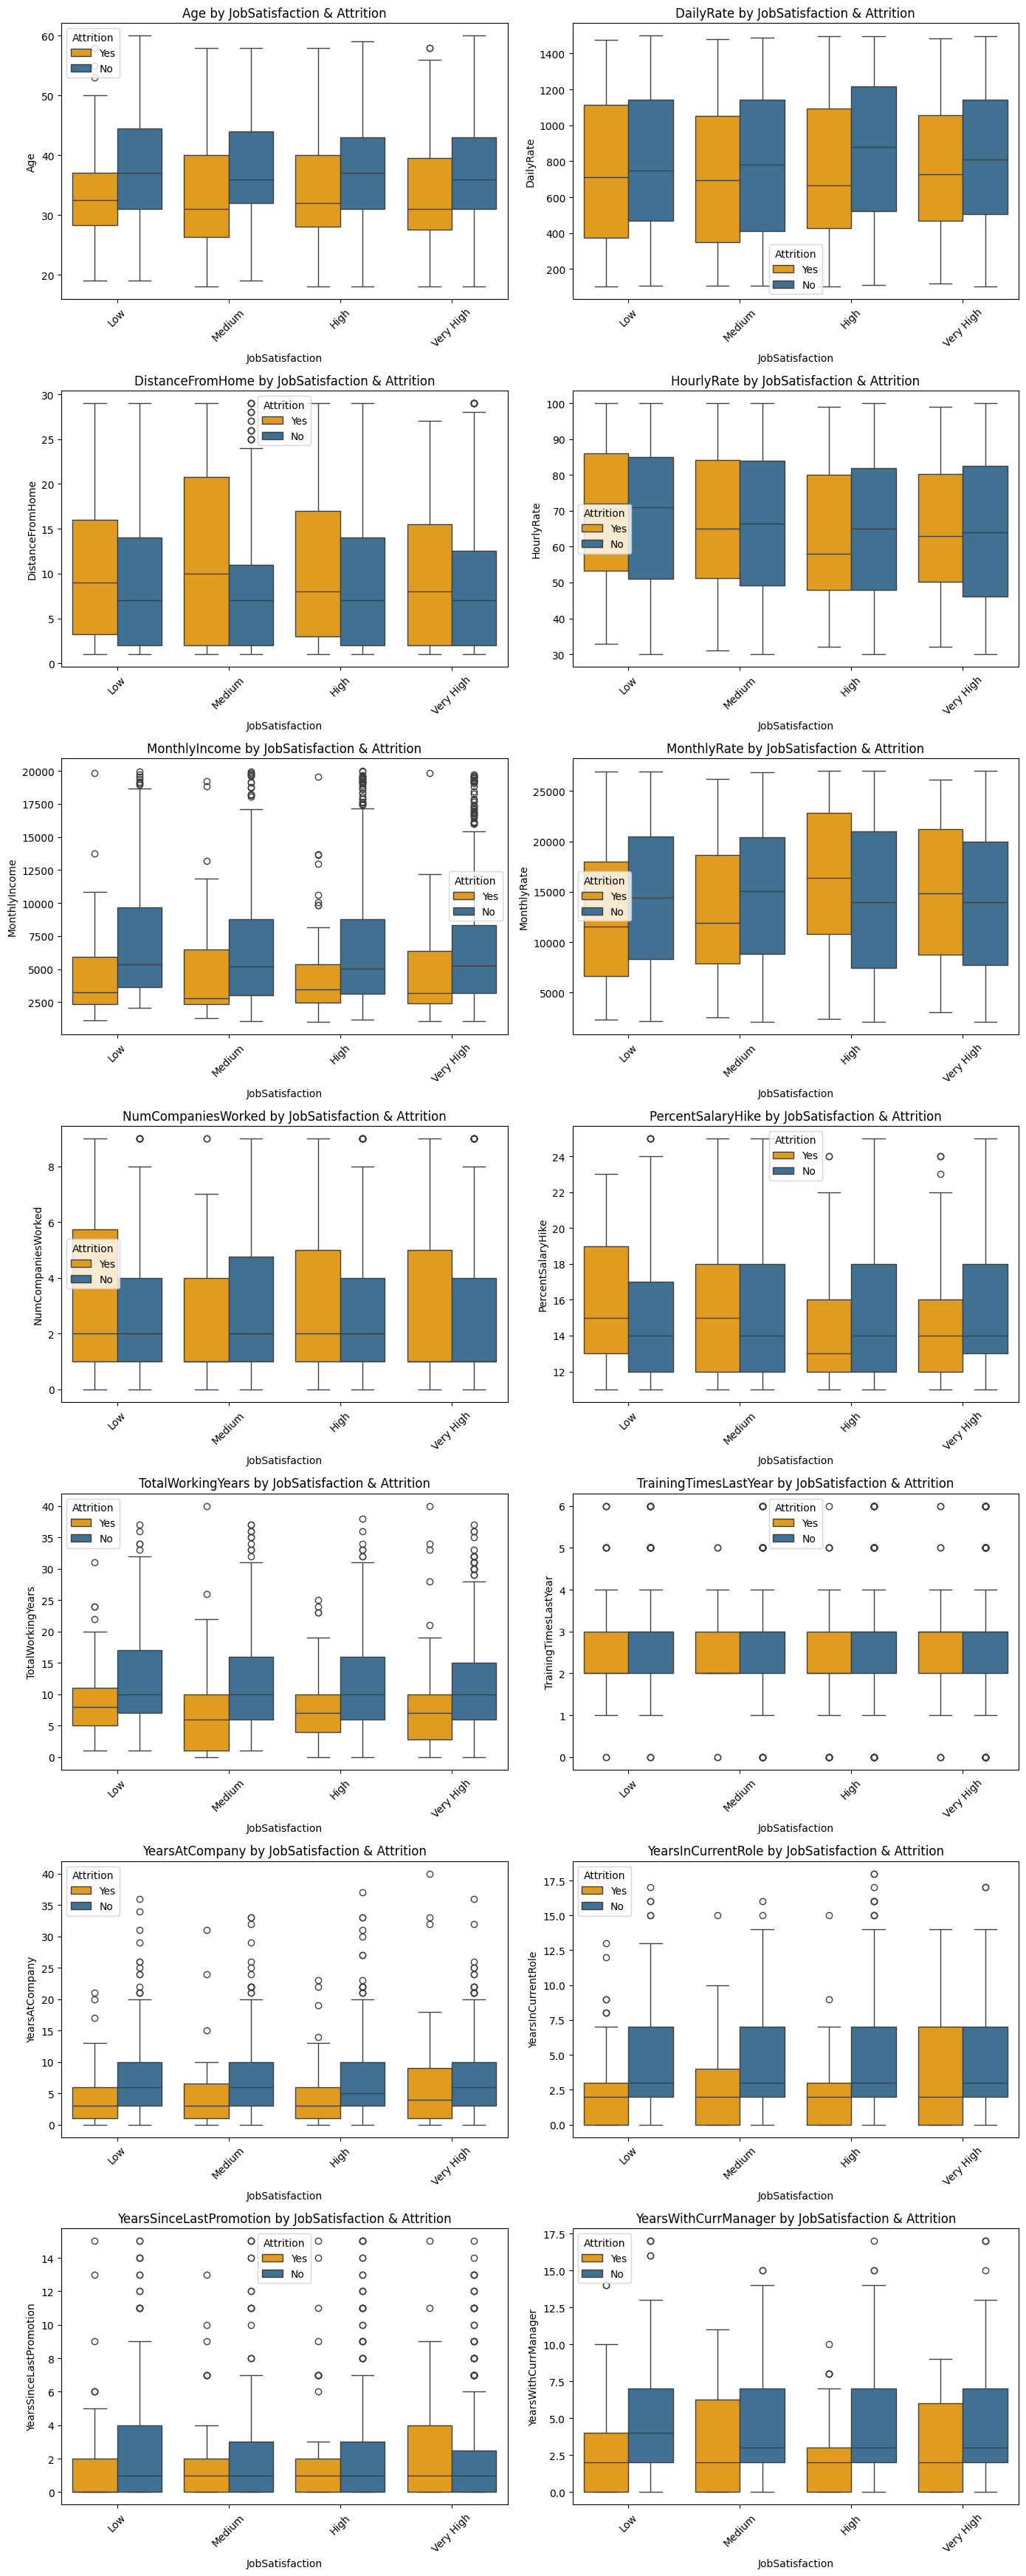

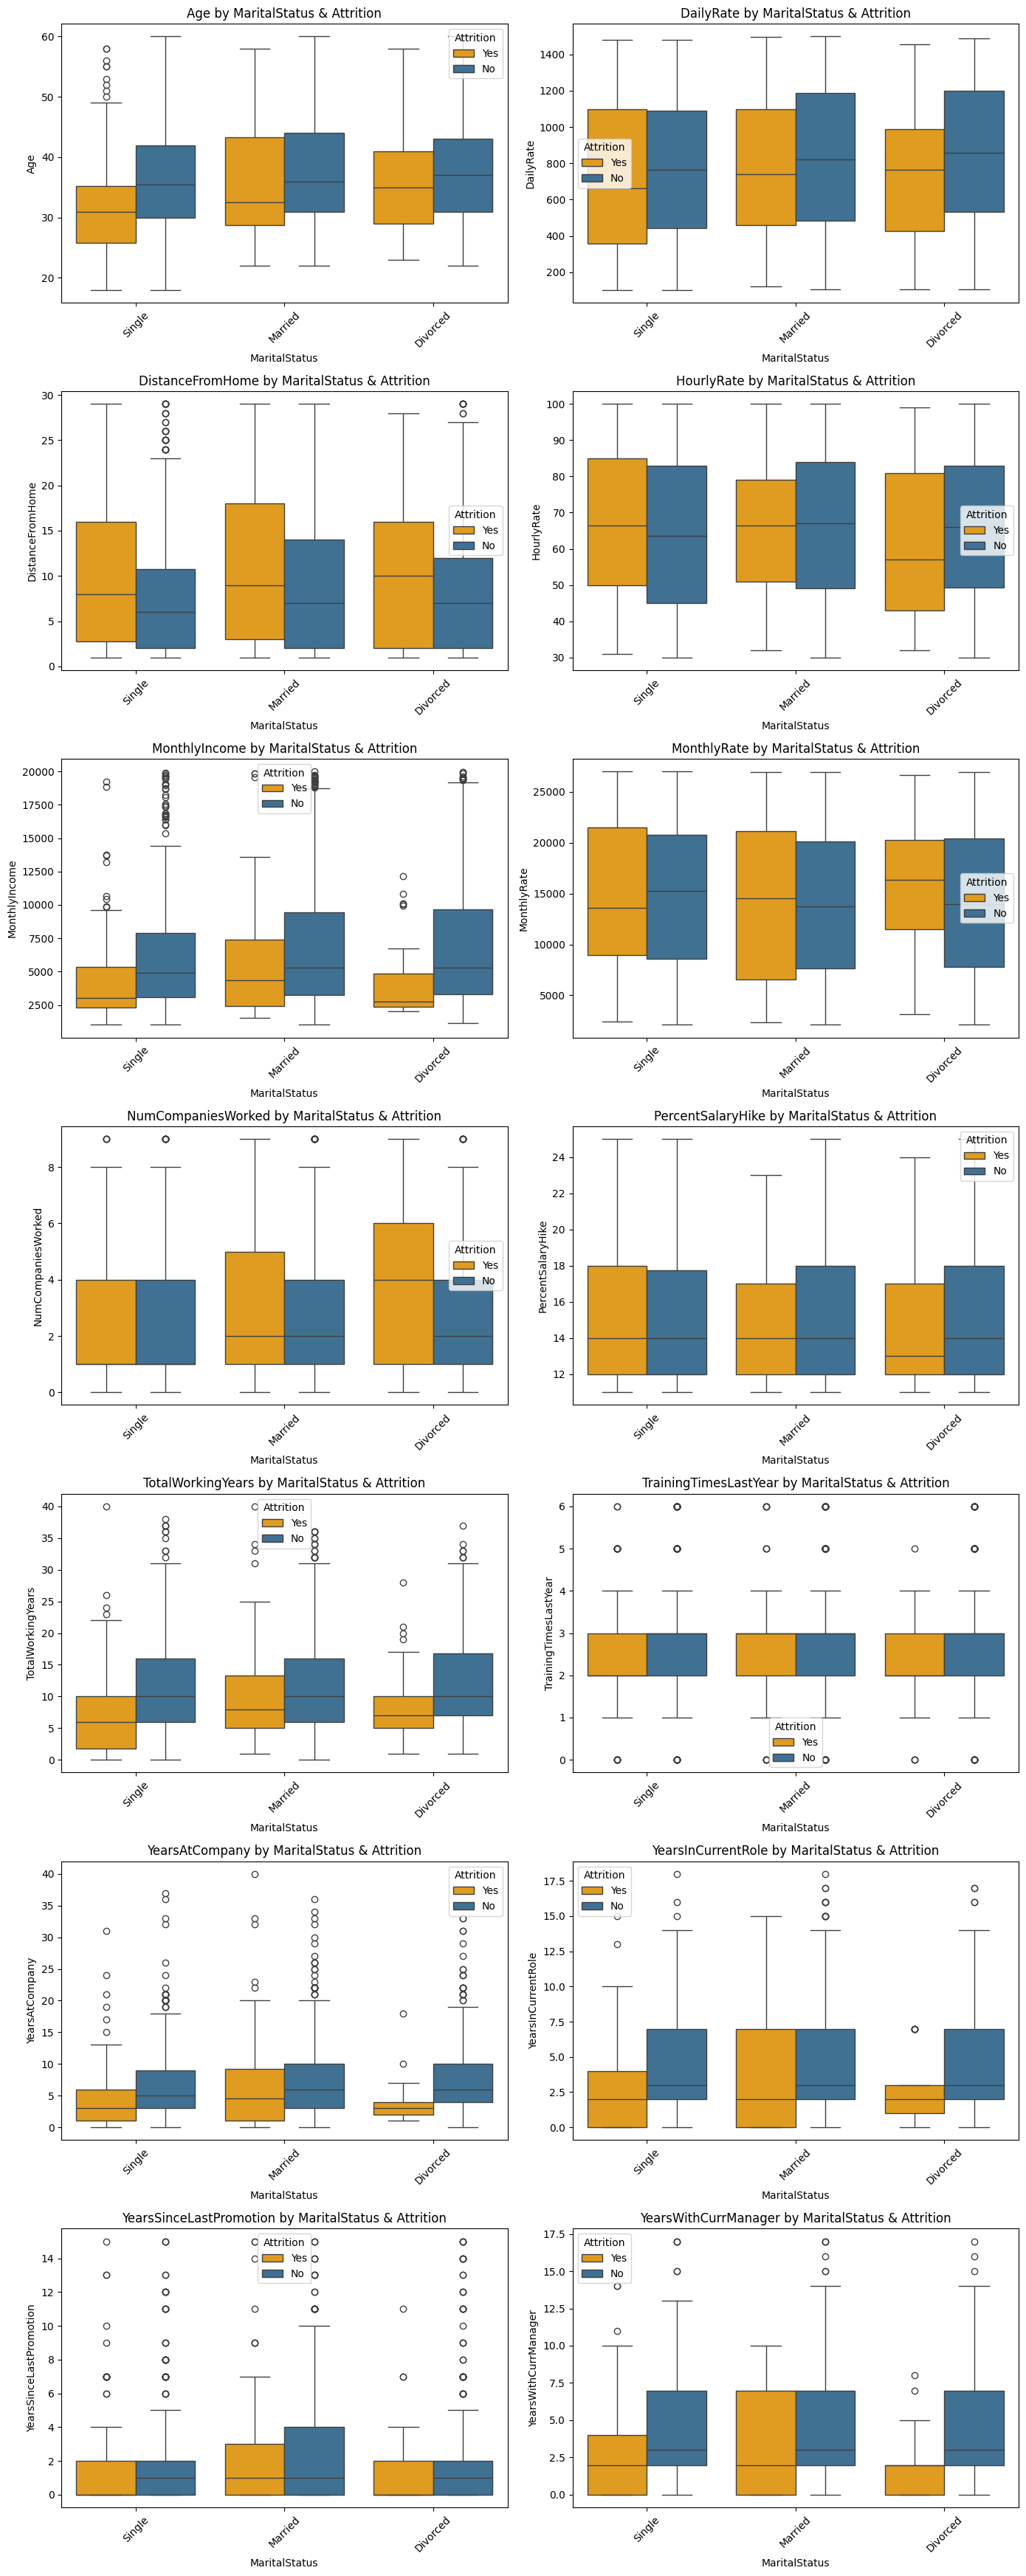

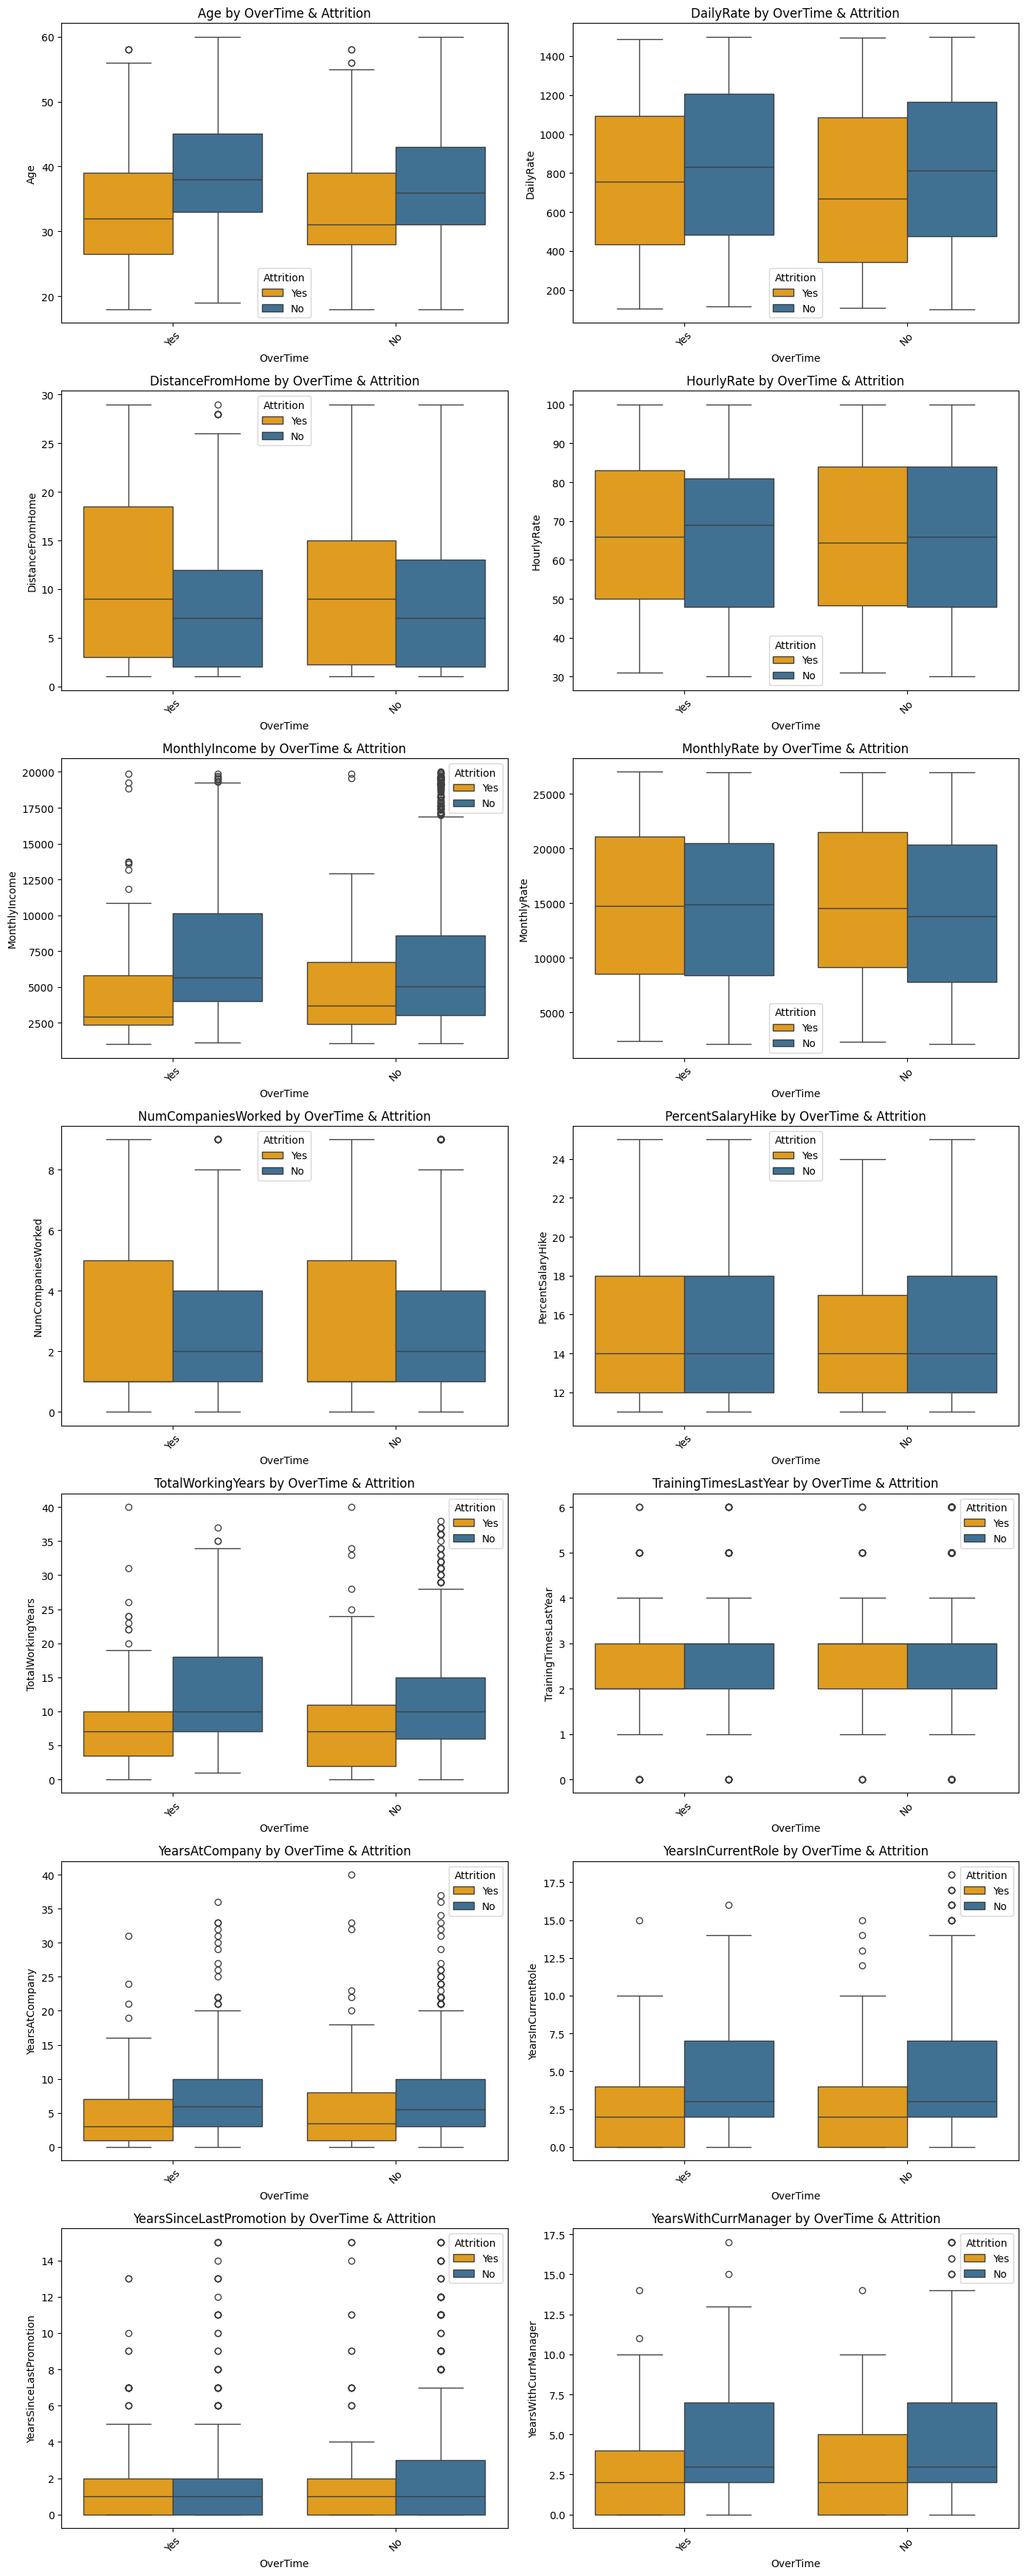

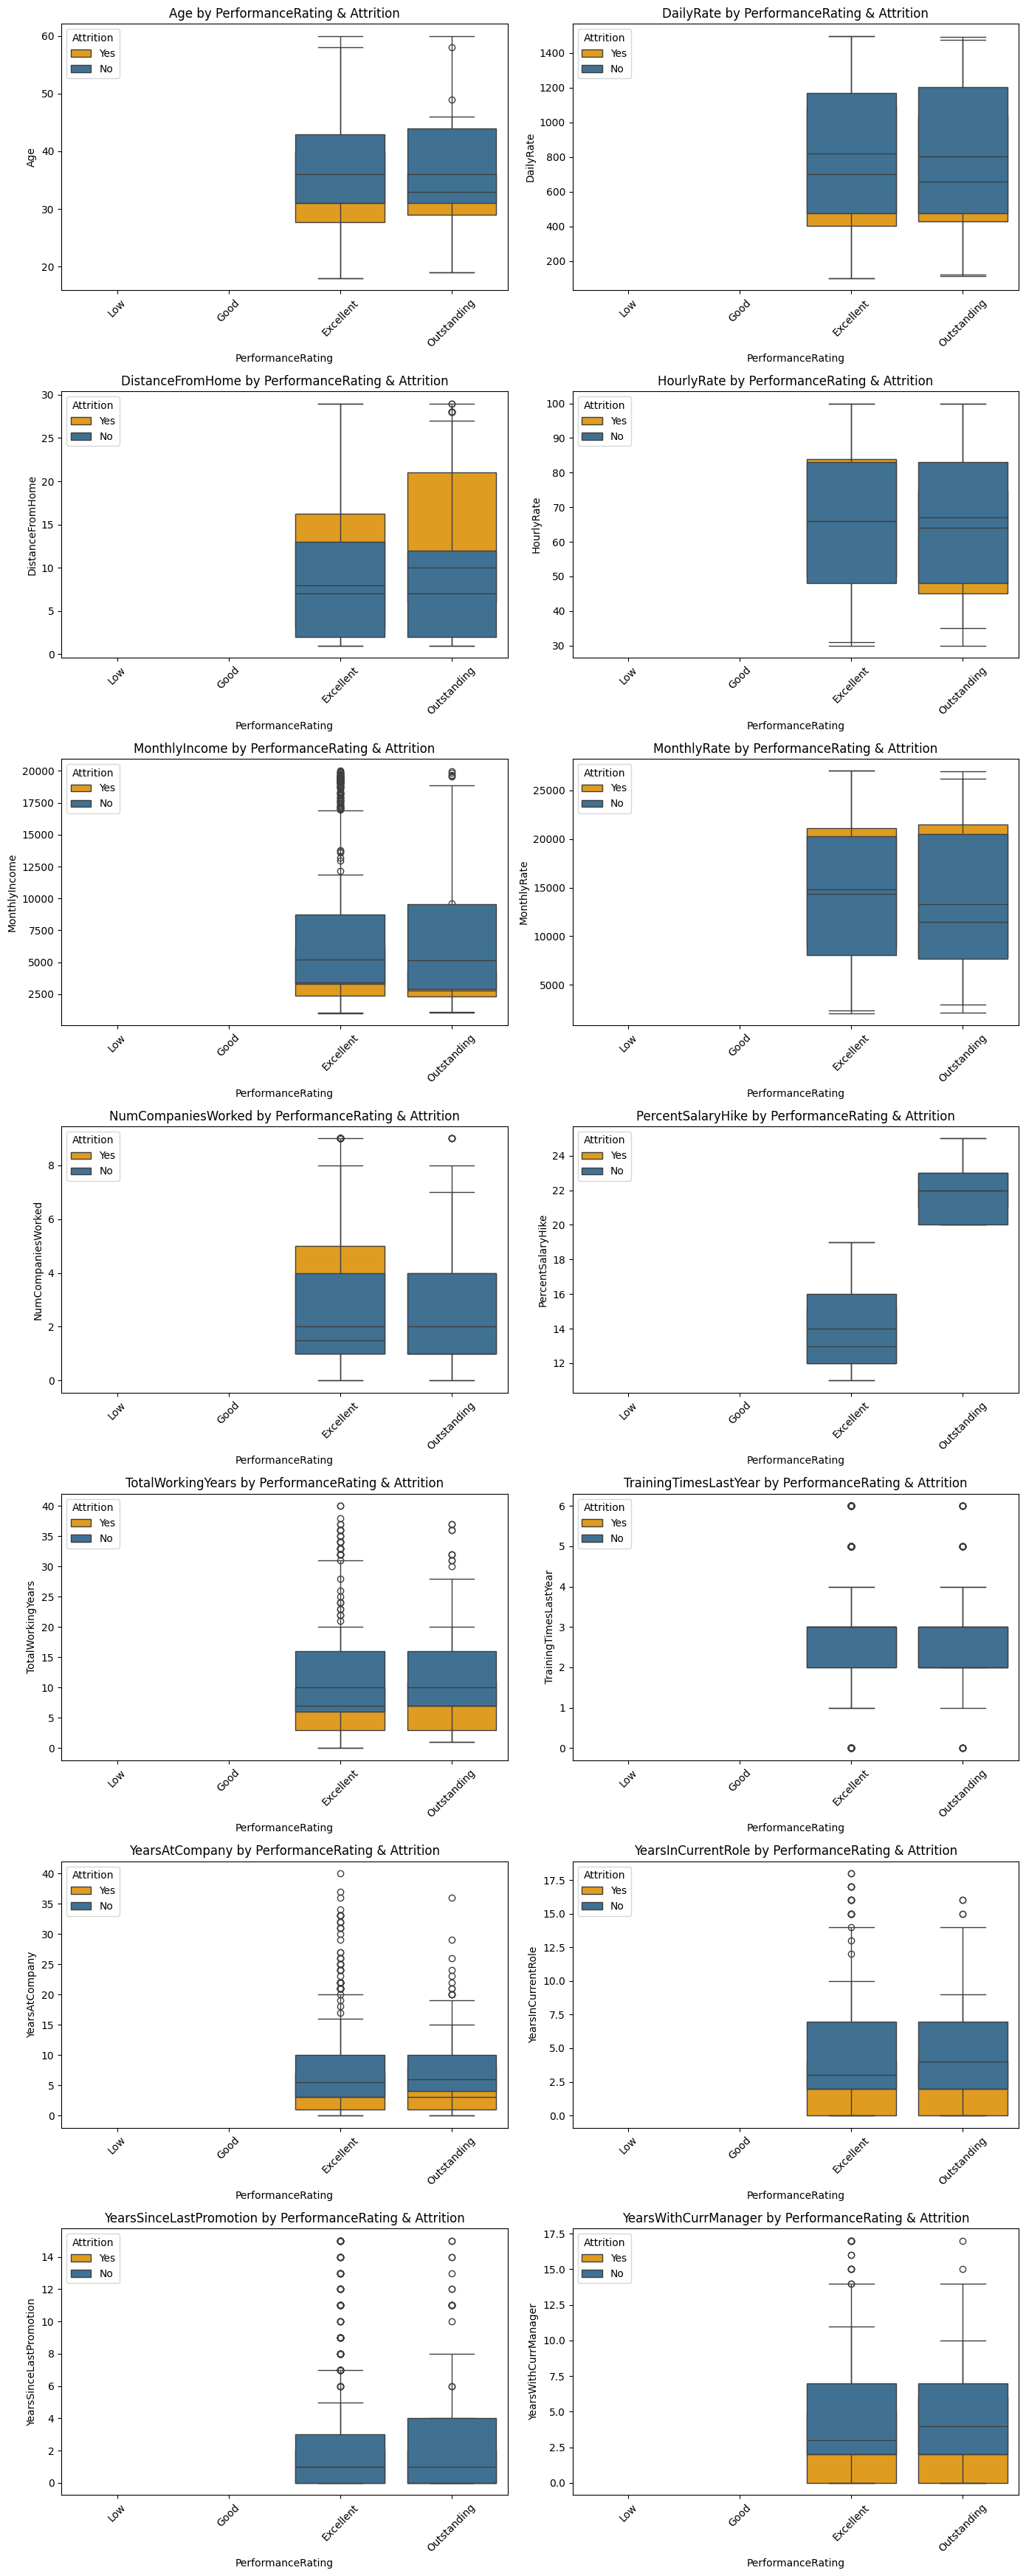

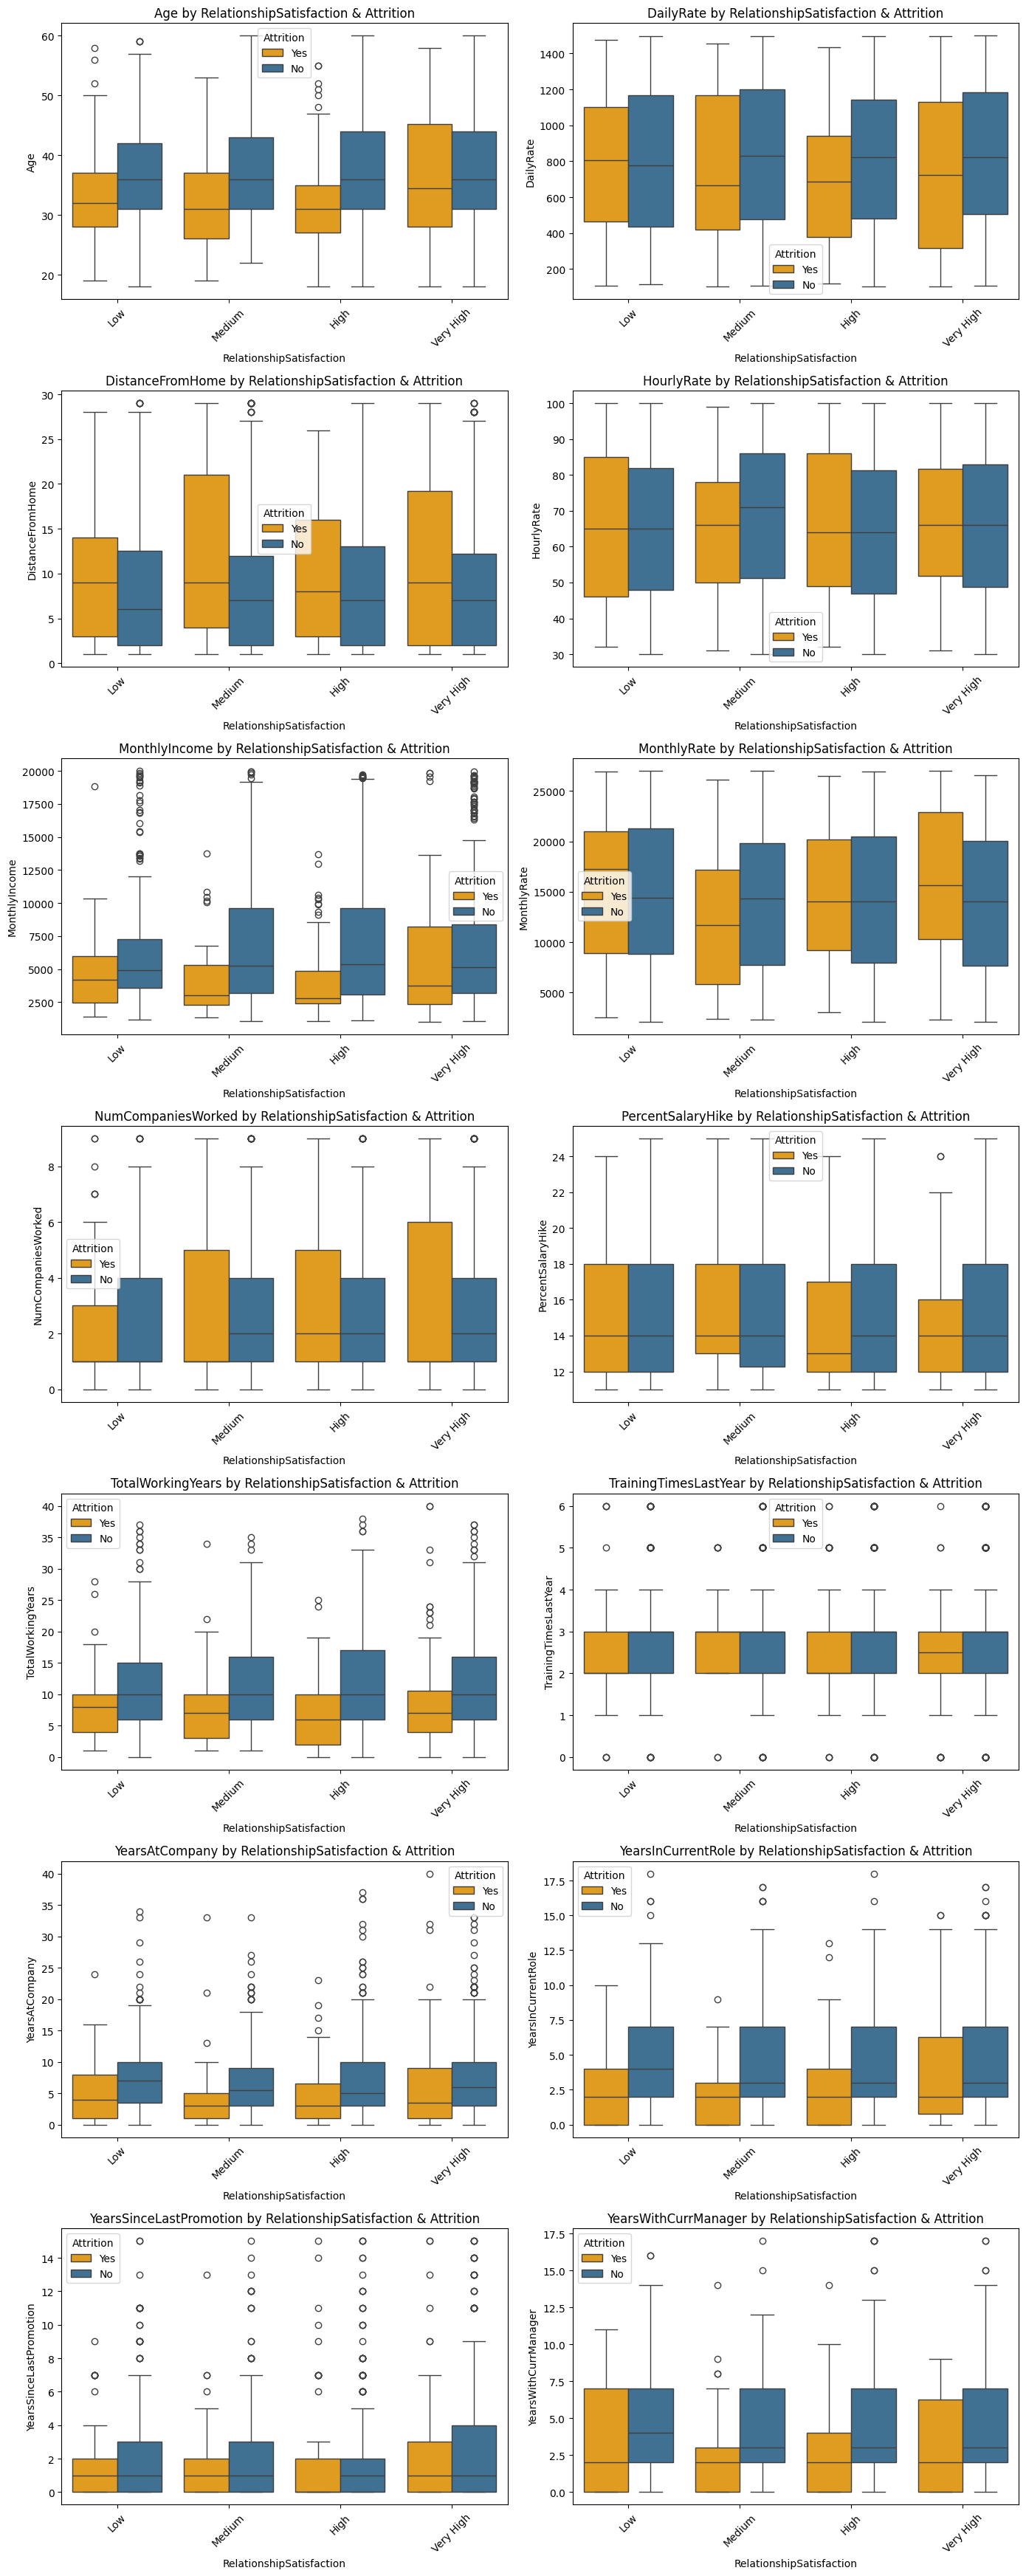

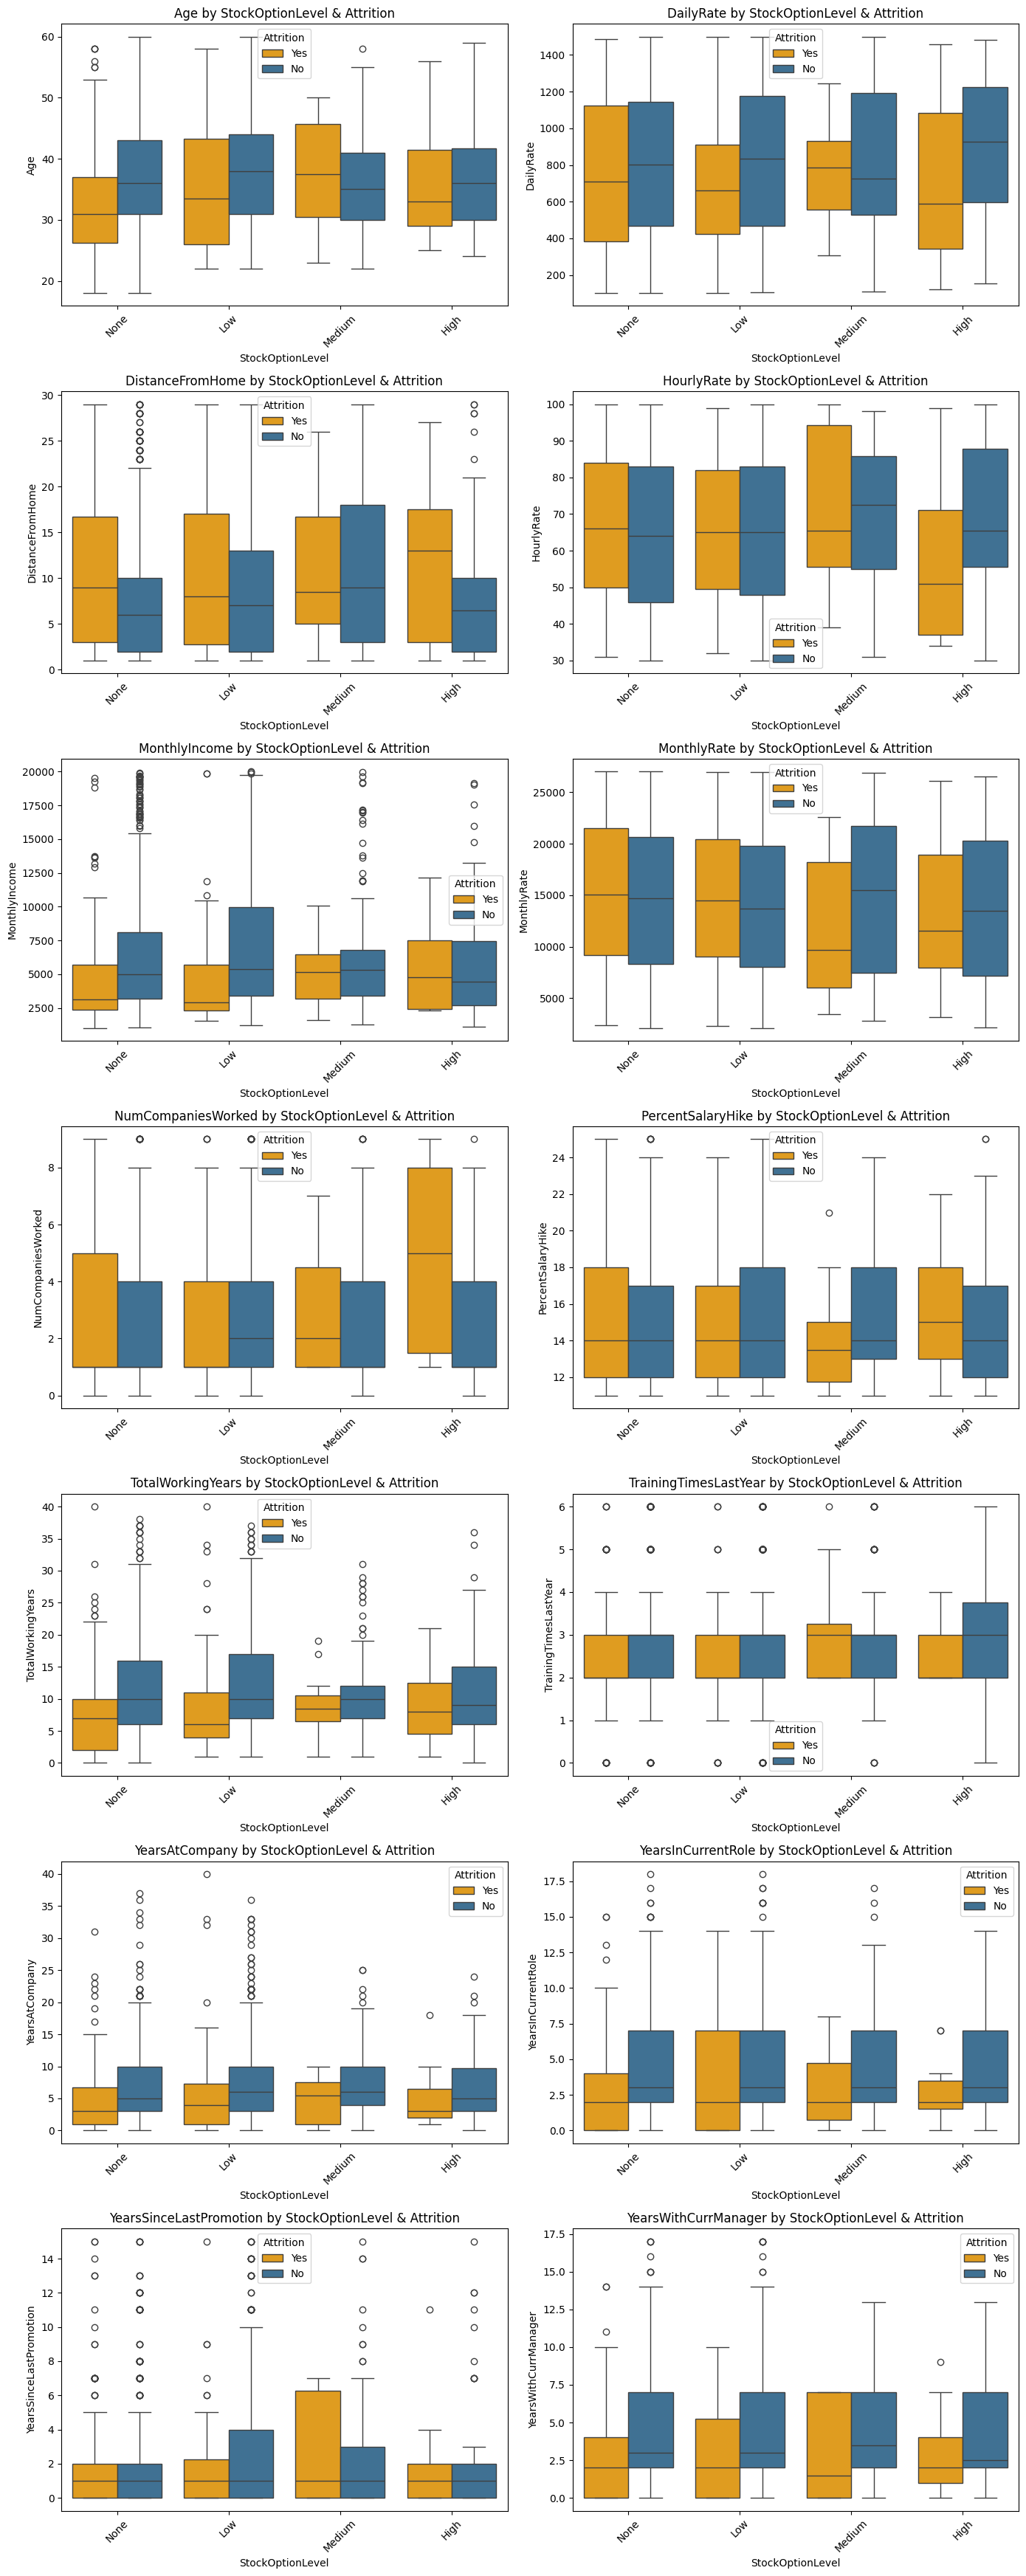

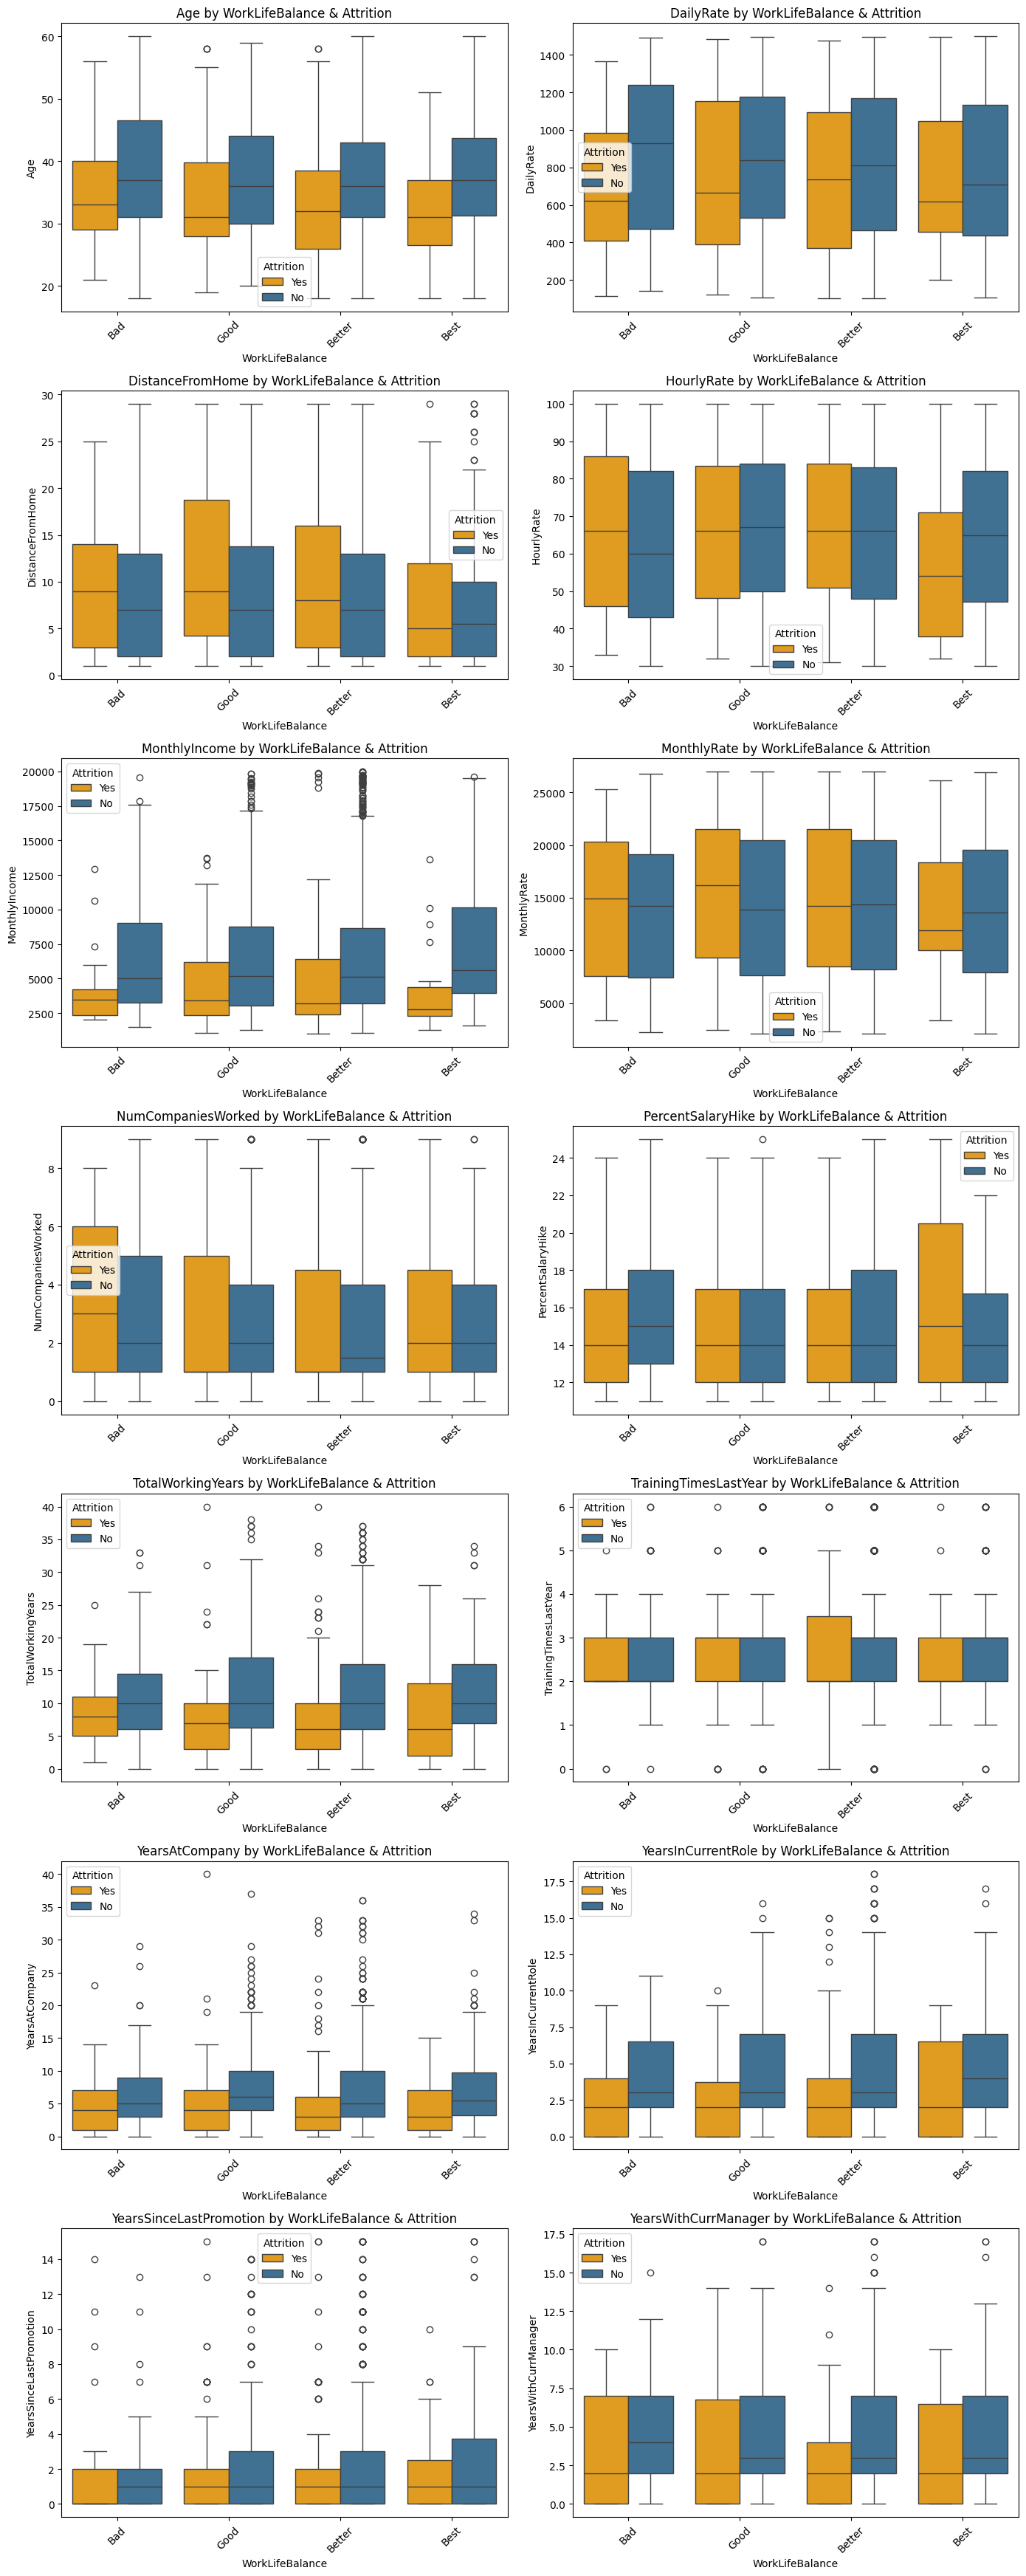

In [45]:

for c in cat_cols:
    n_plots = len(num_cols)
    n_cols = 2  # number of plots per row
    n_rows = math.ceil(n_plots / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7*n_cols, 5*n_rows))
    axes = axes.flatten()  # flatten for easy indexing
    
    for idx, n in enumerate(num_cols):
        sns.boxplot(
            data=df,
            x=c,
            y=n,
            hue="Attrition",
            ax=axes[idx],
            palette=color_map
        )
        axes[idx].tick_params(axis='x', rotation=45)
        axes[idx].set_title(f"{n} by {c} & Attrition")
    
    # Remove unused axes if any
    for i in range(len(num_cols), len(axes)):
        fig.delaxes(axes[i])
    
    plt.tight_layout()
    plt.show()  # one figure per categorical variable

# THE LAB

Employees Count : 1470

In [ ]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [ ]:
df["Attrition"].value_counts(normalize=True).mul(100)

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

We have around 16% attrition rate

lets see which department has most attretions

In [ ]:
df.groupby(by='Department').size()

Department
Human Resources            63
Research & Development    961
Sales                     446
dtype: int64

In [ ]:
df.groupby('Department')['Attrition'].size()

Department
Human Resources            63
Research & Development    961
Sales                     446
Name: Attrition, dtype: int64

In [ ]:
department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

department_attrition

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


In [ ]:
attrition_rate = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("Department")["Left"]
      .mean()
      .mul(100)
      .reset_index(name="AttritionRate")
)

attrition_rate

,Department,AttritionRate
0,Human Resources,19.047619
1,Research & Development,13.839750
2,Sales,20.627803


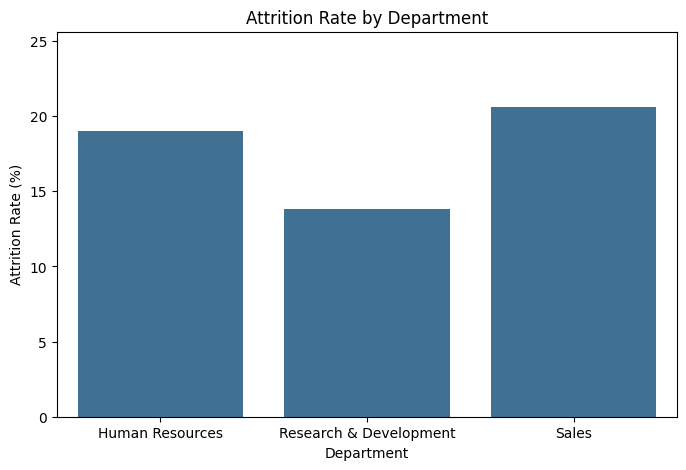

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=attrition_rate,
    x="Department",
    y="AttritionRate",
    color="#3274A1"
)

plt.ylabel("Attrition Rate (%)")
plt.xlabel("Department")
plt.title("Attrition Rate by Department")
plt.ylim(0, attrition_rate["AttritionRate"].max() + 5)
plt.show()

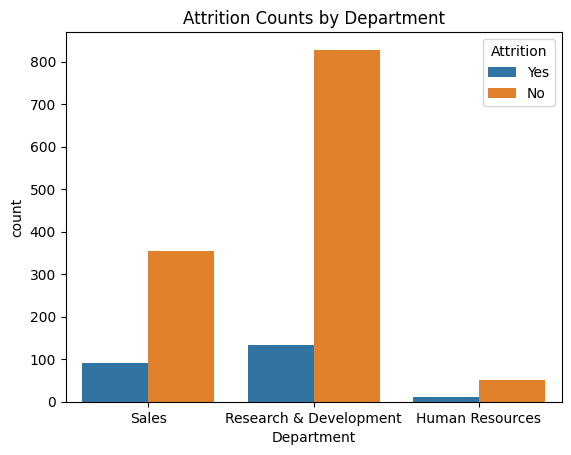

In [ ]:
sns.countplot(
    data=df,
    x="Department",
    hue="Attrition"
)

plt.title("Attrition Counts by Department")
plt.show()